#FMA Small Analysis
**Daniel Bruning - 10/26/2026**



## Imports

In [97]:
from pathlib import Path
import re

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import t, ttest_rel

RESULTS_DIR = Path("results/fma_small")

architectures = sorted(
    [
        p.name
        for p in RESULTS_DIR.iterdir()
        if p.is_dir()
    ]
)

GENRES = [
    "electronic",
    "experimental",
    "folk",
    "hip-hop",
    "instrumental",
    "international",
    "pop",
    "rock"
]

## Helper functions

In [98]:
def display_table(df, decimals=4):
    display(
        df.style
          .hide(axis="index")
          .format(precision=decimals)
    )

# 1. Experimental Artifacts and Data Assembly

## Inventory Dataframe

This dataframe inventories the experimental artifacts generated for each architecture, including duration results, genre results, training histories, metadata files, and confusion matrices. It provides a reproducibility check and helps verify all expected outputs were successfully generated prior to analysis.

In [99]:
inventory_records = []

for model in architectures:
    model_path = RESULTS_DIR / model

    inventory_records.append({
        "model": model,
        "duration_results": len(
            list(
                (model_path / "duration_results").glob("*")
            )
        ),
        "histories": len(
            list(
                (model_path / "histories").glob("*")
            )
        ),
        "metadata": len(
            list(
                (model_path / "metadata").glob("*")
            )
        ),
        "confusion_matrices": len(
            list(
                (model_path / "confusion_matrices").glob("*")
            )
        )
    })

artifact_inventory_df = pd.DataFrame(inventory_records)

# display_table(artifact_inventory_df)

## Metadata Dataframe

This dataframe contains architecture-level metadata and training configuration information including parameter counts, input dimensions, and dataset characteristics. It serves as reference for model specifications throughout the analysis.


In [100]:
metadata_frames = []

for model in architectures:

    metadata_files = list(
        (
            RESULTS_DIR
            / model
            / "metadata"
        ).glob("*.csv")
    )

    for file in metadata_files:
        metadata_frames.append(
            pd.read_csv(file)
        )

model_metadata_df = pd.concat(
    metadata_frames,
    ignore_index=True
)
display_table(model_metadata_df)

model,model_category,pretrained,parameter_count,input_height,input_width,channels,num_classes,learning_rate
cnn,scratch_cnn,False,129224,128,128,3,8,0.0010
crnn,temporal_model,False,345096,128,128,3,8,0.0001
mobilenetv2,pretrained_cnn,True,2587976,224,224,3,8,0.0001
vit,vision_transformer,True,1420680,224,224,3,8,0.0001


## Run Metrics Dataframe

This dataframe consolidates run-level experimental results across architectures, durations, and random seeds. It includes training, validation, and test metrics as well as engineered features used throughout the performance, efficiency, and generalization analyses.


In [101]:
run_frames = []

for model in architectures:

    summary_file = (
        RESULTS_DIR
        / model
        / "duration_results"
        / f"{model}_experiment_summary_all.csv"
    )

    if summary_file.exists():
        run_frames.append(
            pd.read_csv(summary_file)
        )

run_summaries_df = pd.concat(
    run_frames,
    ignore_index=True
)

run_summaries_df["duration_seconds"] = (
    run_summaries_df["duration"]
    .str.replace("s", "", regex=False)
    .astype(int)
)


run_summaries_df["params_million"] = (
    run_summaries_df["parameter_count"] / 1_000_000
)

run_summaries_df["accuracy_per_million_params"] = (
    run_summaries_df["test_accuracy"]
    /
    run_summaries_df["params_million"]
)

run_summaries_df["convergence_speed"] = (
    run_summaries_df["best_epoch"]
    /
    run_summaries_df["epochs_completed"]
)

run_summaries_df["abs_generalization_gap"] = (
    run_summaries_df["generalization_gap"].abs()
)
display_table(run_summaries_df.head(20))

run_name,model,seed,duration,model_category,pretrained,parameter_count,learning_rate,epochs_completed,best_epoch,training_seconds,best_val_accuracy,best_val_loss,test_accuracy,test_balanced_accuracy,test_precision,test_recall,test_f1,test_top2_accuracy,test_top3_accuracy,test_kappa,final_train_accuracy,final_train_loss,final_val_accuracy,final_val_loss,accuracy_gain,generalization_gap,best_epoch_fraction,overfitting_flag,duration_seconds,params_million,accuracy_per_million_params,convergence_speed,abs_generalization_gap
cnn_1s_s42,cnn,42,1s,scratch_cnn,False,129224,0.0010,21,16,345.3057,0.4204,1.6140,0.4098,0.4099,0.4503,0.4099,0.3871,0.6177,0.7554,0.3255,0.5572,1.2532,0.3520,1.8555,0.2952,0.2053,0.7619,True,1,0.1292,3.1716,0.7619,0.2053
cnn_3s_s42,cnn,42,3s,scratch_cnn,False,129224,0.0010,12,7,159.4128,0.4382,1.5008,0.4574,0.4577,0.4873,0.4577,0.4426,0.6686,0.7863,0.3799,0.5481,1.2899,0.3364,2.4494,0.3139,0.2117,0.5833,True,3,0.1292,3.5398,0.5833,0.2117
cnn_5s_s42,cnn,42,5s,scratch_cnn,False,129224,0.0010,15,10,209.0712,0.4341,1.6307,0.4357,0.4360,0.5195,0.4360,0.4139,0.6419,0.7621,0.3551,0.5806,1.2047,0.4107,1.7036,0.2721,0.1699,0.6667,False,5,0.1292,3.3719,0.6667,0.1699
cnn_10s_s42,cnn,42,10s,scratch_cnn,False,129224,0.0010,12,7,162.7683,0.4649,1.5300,0.4474,0.4479,0.4795,0.4479,0.4171,0.6477,0.7705,0.3685,0.5539,1.2710,0.4508,1.5872,0.3406,0.1032,0.5833,False,10,0.1292,3.4623,0.5833,0.1032
cnn_15s_s42,cnn,42,15s,scratch_cnn,False,129224,0.0010,12,7,161.4142,0.4199,1.6690,0.4240,0.4240,0.4926,0.4240,0.4166,0.6060,0.7304,0.3417,0.5638,1.2599,0.3464,1.7716,0.2955,0.2174,0.5833,True,15,0.1292,3.2814,0.5833,0.2174
cnn_20s_s42,cnn,42,20s,scratch_cnn,False,129224,0.0010,30,26,406.9413,0.4791,1.5801,0.4775,0.4773,0.5510,0.4773,0.4762,0.6553,0.7721,0.4027,0.7019,0.8261,0.4332,2.1919,0.3548,0.2686,0.8667,True,20,0.1292,3.6948,0.8667,0.2686
cnn_25s_s42,cnn,42,25s,scratch_cnn,False,129224,0.0010,12,7,164.1638,0.3823,1.8625,0.3890,0.3890,0.5666,0.3890,0.3464,0.5735,0.7287,0.3017,0.5586,1.2709,0.3272,1.9130,0.2579,0.2314,0.5833,True,25,0.1292,3.0101,0.5833,0.2314
cnn_30s_s42,cnn,42,30s,scratch_cnn,False,129224,0.0010,19,14,259.1270,0.4449,1.5636,0.4482,0.4485,0.5069,0.4485,0.4189,0.6444,0.7471,0.3695,0.6197,1.0957,0.2947,2.1650,0.3205,0.3250,0.7368,True,30,0.1292,3.4688,0.7368,0.3250
cnn_1s_s123,cnn,123,1s,scratch_cnn,False,129224,0.0010,16,11,217.8165,0.4395,1.5987,0.4249,0.4250,0.4540,0.4250,0.4149,0.6119,0.7429,0.3427,0.5485,1.2899,0.3344,1.8722,0.2994,0.2140,0.6875,True,1,0.1292,3.2879,0.6875,0.2140
cnn_3s_s123,cnn,123,3s,scratch_cnn,False,129224,0.0010,15,10,211.9055,0.4207,1.6003,0.4023,0.4028,0.4810,0.4028,0.3817,0.6244,0.7621,0.3171,0.5775,1.2099,0.3948,1.8289,0.2963,0.1827,0.6667,False,3,0.1292,3.1135,0.6667,0.1827


## Confusion Matrix Dataframe

This dataframe converts saved confusion matrices into a long-format representation suitable for aggregation and error analysis. Each observation represents the number of samples assigned from one genre to another for a specific architecture, duration, and seed.



In [102]:
confusion_records = []

for model in architectures:

    matrix_dir = (
        RESULTS_DIR
        / model
        / "confusion_matrices"
    )

    for matrix_file in matrix_dir.glob("*.npy"):

        if matrix_file.name.startswith("._"):
            continue

        try:
            matrix = np.load(matrix_file)
        except Exception as e:
            print(
                f"Skipping {matrix_file.name}: {e}"
            )
            continue

        match = re.search(
            r"confusion_matrix_(\d+)s_seed_(\d+)",
            matrix_file.name
        )

        if match is None:
            continue

        duration = int(match.group(1))
        seed = int(match.group(2))

        for i, actual in enumerate(GENRES):
            for j, predicted in enumerate(GENRES):

                confusion_records.append({
                    "model": model,
                    "duration": duration,
                    "seed": seed,
                    "actual": actual,
                    "predicted": predicted,
                    "count": matrix[i, j]
                })

confusion_matrix_long_df = pd.DataFrame(
    confusion_records
)

# confusion_matrix_long_df

## Genre Duration Dataframe

This dataframe contains genre-specific recall values across architectures and audio durations. It serves as the source for evaluating how additional clip length affects classification performance for individual genres.


In [103]:
total_by_genre = (
    confusion_matrix_long_df
    .groupby(
        ["model", "duration", "actual"]
    )["count"]
    .sum()
)

correct_by_genre = (
    confusion_matrix_long_df[
        confusion_matrix_long_df["actual"]
        == confusion_matrix_long_df["predicted"]
    ]
    .groupby(
        ["model", "duration", "actual"]
    )["count"]
    .sum()
)

genre_duration_recall_df = (
    (correct_by_genre / total_by_genre)
    .reset_index()
)

genre_duration_recall_df.columns = [
    "model",
    "duration",
    "genre",
    "recall"
]

genre_duration_recall_df = (
    genre_duration_recall_df
    .sort_values(
        ["model", "duration", "genre"]
    )
    .reset_index(drop=True)
)

# genre_duration_recall_df.head()

## Genre Recall by Model Dataframe

This dataframe summarizes mean recall performance for each genre across architectures. It highlights architecture-specific strengths and weaknesses and supports comparisons of genre recognition capability.

In [104]:
total_by_model_genre = (
    confusion_matrix_long_df
    .groupby(
        ["model", "actual"]
    )["count"]
    .sum()
)

correct_by_model_genre = (
    confusion_matrix_long_df[
        confusion_matrix_long_df["actual"]
        ==
        confusion_matrix_long_df["predicted"]
    ]
    .groupby(
        ["model", "actual"]
    )["count"]
    .sum()
)

genre_recall_by_model_df = (
    (
        correct_by_model_genre
        /
        total_by_model_genre
    )
    .reset_index()
)

genre_recall_by_model_df.columns = [
    "model",
    "genre",
    "recall"
]

# display_table(genre_recall_by_model_df)

## Genre Confusion Dataframe

This dataframe aggregates confusion matrix observations to quantify systematic genre misclassifications. It serves as the primary source for confusion analysis and error-pattern identification.

In [105]:
genre_confusion_summary_df = (
    confusion_matrix_long_df
    .groupby(
        ["model", "actual", "predicted"]
    )["count"]
    .sum()
    .reset_index()
)

genre_confusion_summary_df["actual_total"] = (
    genre_confusion_summary_df
    .groupby(
        ["model", "actual"]
    )["count"]
    .transform("sum")
)

genre_confusion_summary_df[
    "confusion_rate"
] = (
    genre_confusion_summary_df["count"]
    /
    genre_confusion_summary_df["actual_total"]
)

# genre_confusion_summary_df.head()

## Duration Improvement Dataframe

This dataframe captures paired performance changes between 1-second and 30-second excerpts for each architecture and random seed. These observations support duration-effect analyses, significance testing, and effect-size estimation.


In [106]:
metric_cols = [
    "test_accuracy",
    "test_f1",
    "test_precision",
    "test_recall"
]

duration_improvement_records = []

for (model, seed), group in (
    run_summaries_df.groupby(
        ["model", "seed"]
    )
):

    one_sec = group[
        group["duration_seconds"] == 1
    ]

    thirty_sec = group[
        group["duration_seconds"] == 30
    ]

    if one_sec.empty or thirty_sec.empty:
        continue

    record = {
        "model": model,
        "seed": seed,
    }

    for metric in metric_cols:

        base = one_sec.iloc[0][metric]
        final = thirty_sec.iloc[0][metric]

        record[f"{metric}_1s"] = base
        record[f"{metric}_30s"] = final
        record[f"{metric}_gain"] = final - base

    duration_improvement_records.append(record)

duration_improvement_df = pd.DataFrame(
    duration_improvement_records
)

# duration_improvement_df.head()

## Duration Performance

This dataframe summarizes classification performance across audio durations regardless of architecture. It directly supports the central research question regarding the effect of clip length on music genre recognition.

In [107]:
duration_performance_df = (
    run_summaries_df
    .groupby("duration_seconds")
    .agg(
        mean_accuracy=("test_accuracy", "mean"),
        std_accuracy=("test_accuracy", "std"),

        mean_f1=("test_f1", "mean"),
        std_f1=("test_f1", "std"),

        mean_precision=("test_precision", "mean"),
        mean_recall=("test_recall", "mean"),

        mean_generalization_gap=(
            "generalization_gap",
            "mean"
        ),

        mean_training_seconds=(
            "training_seconds",
            "mean"
        ),

        n_runs=("test_accuracy", "count")
    )
    .reset_index()
)

duration_performance_df["sem_accuracy"] = (
    duration_performance_df["std_accuracy"]
    / np.sqrt(duration_performance_df["n_runs"])
)

duration_performance_df["accuracy_ci95"] = (
    1.96
    * duration_performance_df["sem_accuracy"]
)

duration_performance_df["accuracy_ci95_lower"] = (
    duration_performance_df["mean_accuracy"]
    - duration_performance_df["accuracy_ci95"]
)

duration_performance_df["accuracy_ci95_upper"] = (
    duration_performance_df["mean_accuracy"]
    + duration_performance_df["accuracy_ci95"]
)

duration_performance_df = (
    duration_performance_df
    .sort_values("duration_seconds")
    .reset_index(drop=True)
)

# duration_performance_df

## Duration Gain Summary Dataframe

This dataframe summarizes genre-level recall improvements associated with increased audio duration. Mean gains and confidence intervals are aggregated across experimental repetitions to quantify the magnitude and uncertainty of duration effects.



In [108]:
# --------------------------------------------------
# Seed-level genre recall
# --------------------------------------------------

total = (
    confusion_matrix_long_df
    .groupby(
        [
            "model",
            "seed",
            "duration",
            "actual"
        ]
    )["count"]
    .sum()
)

correct = (
    confusion_matrix_long_df[
        confusion_matrix_long_df["actual"]
        ==
        confusion_matrix_long_df["predicted"]
    ]
    .groupby(
        [
            "model",
            "seed",
            "duration",
            "actual"
        ]
    )["count"]
    .sum()
)

seed_recall = (
    (
        correct
        /
        total
    )
    .reset_index()
)

seed_recall.columns = [
    "model",
    "seed",
    "duration",
    "genre",
    "recall"
]

# --------------------------------------------------
# Duration gain per seed
# --------------------------------------------------

gain_records = []

for (model, genre, seed), group in (
    seed_recall.groupby(
        [
            "model",
            "genre",
            "seed"
        ]
    )
):

    group = group.sort_values(
        "duration"
    )

    try:

        recall_1 = (
            group.loc[
                group["duration"] == 1,
                "recall"
            ]
            .iloc[0]
        )

        recall_30 = (
            group.loc[
                group["duration"] == 30,
                "recall"
            ]
            .iloc[0]
        )

        gain_records.append({
            "model": model,
            "genre": genre,
            "seed": seed,
            "duration_gain": (
                recall_30 - recall_1
            )
        })

    except IndexError:
        pass

gain_df = pd.DataFrame(
    gain_records
)

# --------------------------------------------------
# Confidence intervals
# --------------------------------------------------

summary_records = []

for (model, genre), group in (
    gain_df.groupby(
        ["model", "genre"]
    )
):

    n = len(group)

    mean_gain = (
        group["duration_gain"]
        .mean()
    )

    std_gain = (
        group["duration_gain"]
        .std(ddof=1)
    )

    sem = (
        std_gain
        /
        np.sqrt(n)
    )

    ci95 = (
        t.ppf(0.975, df=n - 1)
        * sem
    )

    summary_records.append({
        "model": model,
        "genre": genre,
        "mean_gain": mean_gain,
        "lower_ci": mean_gain - ci95,
        "upper_ci": mean_gain + ci95,
        "n_seeds": n
    })

duration_recall_gain_summary_df = pd.DataFrame(
    summary_records
)

# display_table(duration_recall_gain_summary_df)

### Confidence Interval Methodology

Confidence intervals were computed from paired recall gains between 1-second and 30-second excerpts. For each genre, recall gains were calculated across all architecture-seed combinations. The mean gain and corresponding 95% confidence interval were estimated using t-distribution values. Genres whose 95% confidence intervals for recall gain remained entirely above zero were considered to exhibit a statistically supported positive
duration effect. Essentially, this looks for evidence longer audio clips improved recall beyond what might reasonably occur due to random chance.

In [109]:
duration_pairs = [
    ("1s", "3s"),
    ("3s", "5s"),
    ("5s", "10s"),
    ("10s", "15s"),
    ("15s", "20s"),
    ("20s", "25s"),
    ("25s", "30s")
]

duration_pair_records = []

for model in run_summaries_df["model"].unique():

    model_df = (
        run_summaries_df[
            run_summaries_df["model"] == model
        ]
    )

    pivot = (
        model_df
        .pivot(
            index="seed",
            columns="duration",
            values="test_accuracy"
        )
    )

    for dur_a, dur_b in duration_pairs:

        if (
            dur_a not in pivot.columns
            or
            dur_b not in pivot.columns
        ):
            continue

        acc_a = pivot[dur_a]
        acc_b = pivot[dur_b]

        gains = acc_b - acc_a

        mean_gain = gains.mean()

        std_gain = gains.std(
            ddof=1
        )

        t_stat, p_value = ttest_rel(
            acc_b,
            acc_a
        )

        cohen_d = (
            mean_gain / std_gain
            if std_gain > 0
            else np.nan
        )

        duration_pair_records.append({

            "Architecture":
                model,

            "Comparison":
                f"{dur_a} → {dur_b}",

            "Mean Gain":
                mean_gain,

            "Std Gain":
                std_gain,

            "t Statistic":
                t_stat,

            "p Value":
                p_value,

            "Cohen's d":
                cohen_d,

            "Significant (p < .05)":
                p_value < 0.05
        })

duration_pairwise_df = (
    pd.DataFrame(
        duration_pair_records
    )
)
display_table(duration_pairwise_df)

Architecture,Comparison,Mean Gain,Std Gain,t Statistic,p Value,Cohen's d,Significant (p < .05)
cnn,1s → 3s,0.0381,0.0501,1.6999,0.1644,0.7602,False
cnn,3s → 5s,-0.0214,0.0344,-1.3895,0.2370,-0.6214,False
cnn,5s → 10s,0.0098,0.0606,0.3634,0.7347,0.1625,False
cnn,10s → 15s,0.0269,0.0482,1.2457,0.2808,0.5571,False
cnn,15s → 20s,-0.0265,0.0583,-1.0187,0.3659,-0.4556,False
cnn,20s → 25s,-0.0048,0.0887,-0.1220,0.9088,-0.0546,False
cnn,25s → 30s,-0.0085,0.0728,-0.2614,0.8067,-0.1169,False
crnn,1s → 3s,0.0269,0.0160,3.7677,0.0196,1.6850,True
crnn,3s → 5s,0.0280,0.0218,2.8774,0.0451,1.2868,True
crnn,5s → 10s,0.0077,0.0197,0.8731,0.4319,0.3904,False


## Architecture Performance Dataframe

This dataframe summarizes overall predictive performance for each architecture across all durations and seeds. It provides the primary basis for identifying the strongest overall classifiers in the study.

In [110]:
architecture_performance_df = (
    run_summaries_df
    .groupby("model")
    .agg(
        mean_accuracy=("test_accuracy", "mean"),
        std_accuracy=("test_accuracy", "std"),

        mean_test_f1=("test_f1", "mean"),
        std_test_f1=("test_f1", "std"),

        mean_test_precision=("test_precision", "mean"),
        mean_test_recall=("test_recall", "mean"),

        mean_generalization_gap=(
            "generalization_gap",
            "mean"
        ),

        mean_best_epoch=(
            "best_epoch",
            "mean"
        ),

        parameter_count=(
            "parameter_count",
            "first"
        )
    )
    .reset_index()
)

architecture_performance_df[
    "parameters_million"
] = (
    architecture_performance_df["parameter_count"]
    / 1_000_000
)

architecture_performance_df = (
    architecture_performance_df
    .sort_values(
        "mean_accuracy",
        ascending=False
    )
)

# architecture_performance_df.head()

## Architecture Duration Dataframe

This dataframe summarizes predictive performance for each architecture at each audio duration. It supports analysis of how classification quality changes as additional clip length becomes available.


In [111]:
architecture_duration_summary_df = (
    run_summaries_df
    .groupby(
        ["model", "duration_seconds"]
    )
    .agg(
        mean_accuracy=("test_accuracy", "mean"),
        std_accuracy=("test_accuracy", "std"),

        mean_test_f1=("test_f1", "mean"),
        std_test_f1=("test_f1", "std"),

        mean_test_precision=("test_precision", "mean"),
        mean_test_recall=("test_recall", "mean"),

        n_runs=("seed", "count")
    )
    .reset_index()
)

architecture_duration_summary_df = (
    architecture_duration_summary_df
    .sort_values(
        ["model", "duration_seconds"]
    )
)

# architecture_duration_summary_df.head()

## Model Efficiency Dataframe

This dataframe evaluates computational efficiency by combining model size, training cost, and predictive performance. It supports comparisons of tradeoffs between accuracy and complexity across architectures.

In [112]:
model_efficiency_df = (
    run_summaries_df
    .groupby("model")
    .agg(
        parameter_count=("parameter_count", "first"),
        params_million=("params_million", "first"),

        mean_accuracy=("test_accuracy", "mean"),
        mean_f1=("test_f1", "mean"),

        mean_training_seconds=(
            "training_seconds",
            "mean"
        ),

        mean_accuracy_per_million=(
            "accuracy_per_million_params",
            "mean"
        )
    )
    .reset_index()
)
# display_table(model_efficiency_df)

## Training Behavior Dataframe

This dataframe characterizes model training dynamics, convergence behavior, and generalization performance. Metrics include training time, convergence speed, generalization gap, and overfitting frequency.

In [113]:
training_behavior_df = (
    run_summaries_df
    .groupby("model")
    .agg(
        mean_best_epoch=("best_epoch", "mean"),
        mean_convergence_speed=("convergence_speed", "mean"),
        mean_training_time=("training_seconds", "mean"),
        mean_accuracy_gain=("accuracy_gain", "mean"),
        mean_generalization_gap=(
            "generalization_gap",
            "mean"
        ),
        mean_abs_gap=(
            "abs_generalization_gap",
            "mean"
        ),
        overfitting_rate=(
            "overfitting_flag",
            "mean"
        )
    )
    .reset_index()
)

# display_table(training_behavior_df)

## Duration Research Dataframe

In [114]:
research_records = []

for model, group in (
    run_summaries_df.groupby("model")
):

    one_sec = group[
        group["duration_seconds"] == 1
    ]

    thirty_sec = group[
        group["duration_seconds"] == 30
    ]

    if one_sec.empty or thirty_sec.empty:
        continue

    mean_acc_1s = one_sec["test_accuracy"].mean()
    mean_acc_30s = thirty_sec["test_accuracy"].mean()

    mean_recall_1s = one_sec["test_recall"].mean()
    mean_recall_30s = thirty_sec["test_recall"].mean()

    gain_row = (
        duration_improvement_df[
            duration_improvement_df["model"]
            == model
        ]
    )

    accuracy_gain_mean = (
        gain_row["test_accuracy_gain"].mean()
    )

    recall_gain_mean = (
        gain_row["test_recall_gain"].mean()
    )

    accuracy_ci = (
        1.96
        * gain_row["test_accuracy_gain"].std(ddof=1)
        / np.sqrt(len(gain_row))
    )

    research_records.append({
        "model": model,

        "mean_accuracy_1s": mean_acc_1s,
        "mean_accuracy_30s": mean_acc_30s,
        "accuracy_gain": accuracy_gain_mean,

        "mean_recall_1s": mean_recall_1s,
        "mean_recall_30s": mean_recall_30s,
        "recall_gain": recall_gain_mean,

        "accuracy_ci_lower":
            accuracy_gain_mean - accuracy_ci,

        "accuracy_ci_upper":
            accuracy_gain_mean + accuracy_ci
    })

duration_research_question_df = pd.DataFrame(
    research_records
)

duration_research_question_df = (
    duration_research_question_df
    .sort_values(
        "accuracy_gain",
        ascending=False
    )
)

display_table(duration_research_question_df)

model,mean_accuracy_1s,mean_accuracy_30s,accuracy_gain,mean_recall_1s,mean_recall_30s,recall_gain,accuracy_ci_lower,accuracy_ci_upper
mobilenetv2,0.4624,0.5205,0.0581,0.4625,0.5207,0.0582,0.0433,0.0729
crnn,0.4082,0.4644,0.0563,0.4082,0.4646,0.0563,0.0363,0.0762
vit,0.3494,0.3669,0.0175,0.3496,0.3671,0.0175,0.0056,0.0295
cnn,0.4130,0.4265,0.0135,0.4131,0.4267,0.0136,-0.0722,0.0992


## Duration Rankings Dataframe

In [115]:
model_duration_rankings_df = (
    architecture_duration_summary_df
    .copy()
)

model_duration_rankings_df["accuracy_rank"] = (
    model_duration_rankings_df
    .groupby("duration_seconds")["mean_accuracy"]
    .rank(
        ascending=False,
        method="dense"
    )
)

model_duration_rankings_df["f1_rank"] = (
    model_duration_rankings_df
    .groupby("duration_seconds")["mean_test_f1"]
    .rank(
        ascending=False,
        method="dense"
    )
)

model_duration_rankings_df["mean_rank"] = (
    model_duration_rankings_df[
        ["accuracy_rank", "f1_rank"]
    ]
    .mean(axis=1)
)

model_duration_rankings_df = (
    model_duration_rankings_df
    .sort_values(
        ["duration_seconds", "mean_rank"]
    )
    .reset_index(drop=True)
)


## Duration Significance Statistics Dataframe

In [116]:
significance_records = []

for model, group in (
    duration_improvement_df
    .groupby("model")
):

    acc_1s = group["test_accuracy_1s"]
    acc_30s = group["test_accuracy_30s"]

    t_stat, p_value = ttest_rel(
        acc_30s,
        acc_1s
    )

    gains = group["test_accuracy_gain"]

    mean_gain = gains.mean()
    std_gain = gains.std(ddof=1)

    # Cohen's d for paired samples
    cohen_d = (
        mean_gain / std_gain
        if std_gain > 0
        else np.nan
    )

    significance_records.append({
        "Architecture": model,
        "Mean Accuracy Gain": mean_gain,
        "Std Gain": std_gain,
        "t Statistic": t_stat,
        "p Value": p_value,
        "Cohen's d": cohen_d,
        "Significant (p < .05)": (
            p_value < 0.05
        )
    })

duration_significance_table = (
    pd.DataFrame(significance_records)
    .sort_values(
        "Mean Accuracy Gain",
        ascending=False
    )
    .reset_index(drop=True)
)

# display_table(duration_significance_table)

# 2. Experimental Inventory and Metadata

## Table 1. Experimental Artifact Inventory

In [117]:
artifact_inventory_table = (
    artifact_inventory_df
    .sort_values("model")
    .rename(
        columns={
            "model": "Architecture",
            "duration_results": "Duration Results",
            "histories": "Training Histories",
            "metadata": "Metadata Files",
            "confusion_matrices": "Confusion Matrices"
        }
    )
)
display_table(
    artifact_inventory_table
)

Architecture,Duration Results,Training Histories,Metadata Files,Confusion Matrices
cnn,41,40,1,40
crnn,41,40,1,40
mobilenetv2,41,40,1,40
vit,42,40,1,40


### Comments
All four architectures produced complete and consistent collections of experimental outputs. Each architecture generated 41 duration-result files, 40 training histories, 1 metadata file, and 40 confusion matrices. The absence of missing artifacts indicates all architectures contributed equally to the downstream analyses and any comparisons are based on complete experimental evidence.



## Table 2. Architecture Metadata

In [118]:
architecture_metadata_table = (
    model_metadata_df[
        [
            "model",
            "model_category",
            "parameter_count",
            "input_height",
            "input_width"
        ]
    ]
    .copy()
)

architecture_metadata_table["parameter_count"] = (
    architecture_metadata_table["parameter_count"]
    .map(lambda x: f"{x:,}")
)

architecture_metadata_table = (
    architecture_metadata_table.rename(
        columns={
            "model": "Architecture",
            "model_category": "Family",
            "parameter_count": "Parameters",
            "input_height": "Height",
            "input_width": "Width"
        }
    )
)
display_table(
    architecture_metadata_table
)

Architecture,Family,Parameters,Height,Width
cnn,scratch_cnn,"129,224",128,128
crnn,temporal_model,"345,096",128,128
mobilenetv2,pretrained_cnn,"2,587,976",224,224
vit,vision_transformer,"1,420,680",224,224


### Comments
The evaluated architectures span multiple neural network families, including conventional convolutional networks (CNN), transfer-learning architectures (MobileNetV2), recurrent networks (CRNN), and transformer models (ViT). Model complexity ranged from 129,224 parameters for CNN to 2,587,976 parameters for MobileNetV2. Input image dimensions were not fully standardized across architectures. CNN and CRNN operated on 128×128 mel spectrograms, whereas MobileNetV2 and ViT utilized 224×224 inputs to accommodate their architectural requirements. As a result, observed performance differences may reflect architectural design choices and differences in input resolution and should be interpreted accordingly.



# 3. Overall Architecture Performance

## Figure 1. Architecture Accuracy and Generalization Tradeoffs

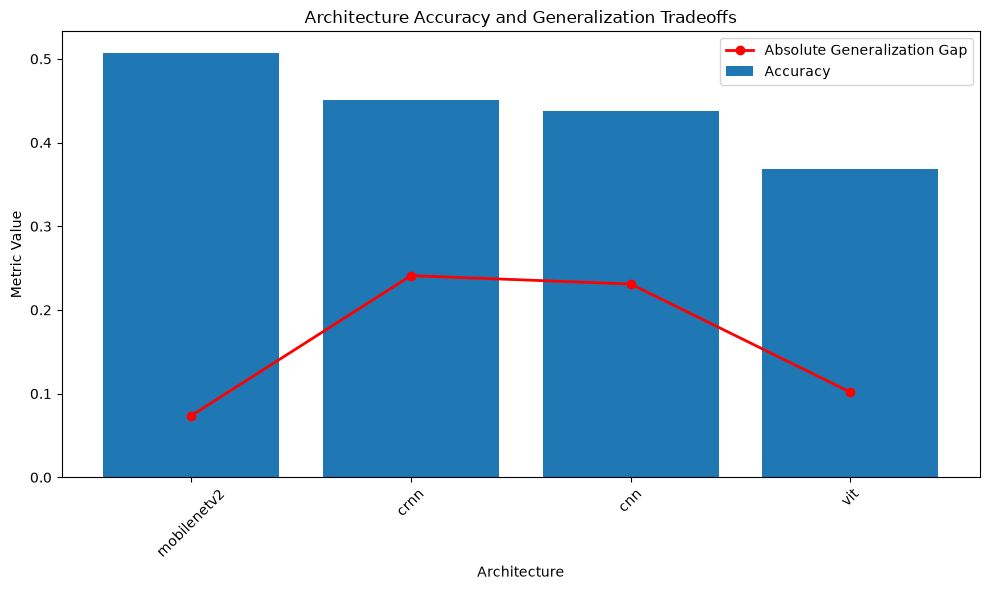

In [119]:
profile_df = (
    training_behavior_df[
        [
            "model",
            "mean_abs_gap"
        ]
    ]
    .merge(
        architecture_performance_df[
            [
                "model",
                "mean_accuracy"
            ]
        ],
        on="model"
    )
    .rename(
        columns={
            "mean_accuracy": "accuracy",
            "mean_abs_gap": "abs_gap"
        }
    )
    .sort_values(
        "accuracy",
        ascending=False
    )
)
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(profile_df))

ax.bar(
    x,
    profile_df["accuracy"],
    label="Accuracy"
)

ax.plot(
    x,
    profile_df["abs_gap"],
    color="red",
    marker="o",
    linewidth=2,
    label="Absolute Generalization Gap"
)

ax.set_xticks(x)
ax.set_xticklabels(
    profile_df["model"],
    rotation=45
)

ax.set_ylabel("Metric Value")
ax.set_xlabel("Architecture")

ax.set_title(
    "Architecture Accuracy and Generalization Tradeoffs"
)

ax.legend()

plt.tight_layout()
plt.show()

### Comments 
MobileNetV2 achieved the highest overall classification accuracy (0.508), followed by CRNN (0.451), CNN (0.438), and ViT (0.369). The FMA Small results favored the transfer-learning approach implemented by MobileNetV2. The architecture simultaneously achieved the highest accuracy, highest F1 score, largest duration-related gain, and lowest observed generalization gap.


## Table 3. Overall Architecture Performance

In [120]:
architecture_performance_table = (
    architecture_performance_df[
        [
            "model",
            "mean_accuracy",
            "mean_test_f1",
            "mean_test_precision",
            "mean_test_recall",
            "parameters_million"
        ]
    ]
    .copy()
)

architecture_performance_table.columns = [
    "Architecture",
    "Accuracy",
    "F1",
    "Precision",
    "Recall",
    "Parameters (M)"
]

architecture_performance_table = (
    architecture_performance_table
    .sort_values(
        "Accuracy",
        ascending=False
    )
)

display_table(
    architecture_performance_table
)

Architecture,Accuracy,F1,Precision,Recall,Parameters (M)
mobilenetv2,0.5075,0.4994,0.5019,0.5077,2.5880
crnn,0.4511,0.4397,0.4503,0.4512,0.3451
cnn,0.4377,0.4154,0.4992,0.4378,0.1292
vit,0.3688,0.3469,0.3588,0.3690,1.4207


### Comments 
MobileNetV2 achieved the strongest overall classification performance, producing the highest accuracy (0.508), F1 score (0.499), precision (0.502), and recall (0.508) among the evaluated architectures. The model contained 2.588 million parameters, making it the largest architecture in the study and the strongest overall performer across the primary evaluation metrics.

CRNN achieved the second-highest classification accuracy (0.451) and F1 score (0.440) while using only 0.345 million parameters, approximately one-seventh the size of MobileNetV2. CNN achieved similar overall performance (0.438 accuracy, 0.415 F1) with the smallest model size in the study (0.129 million parameters), indicating substantially greater parameter efficiency despite lower predictive performance.

ViT produced the lowest overall accuracy (0.369) and F1 score (0.347) despite containing 1.421 million parameters, more than ten times the parameter count of CNN. The transformer architecture therefore did not achieve performance comparable to the convolutional and recurrent architectures under the evaluated training conditions.

## Figure 2. Test Accuracy Distribution by Architecture and Seed

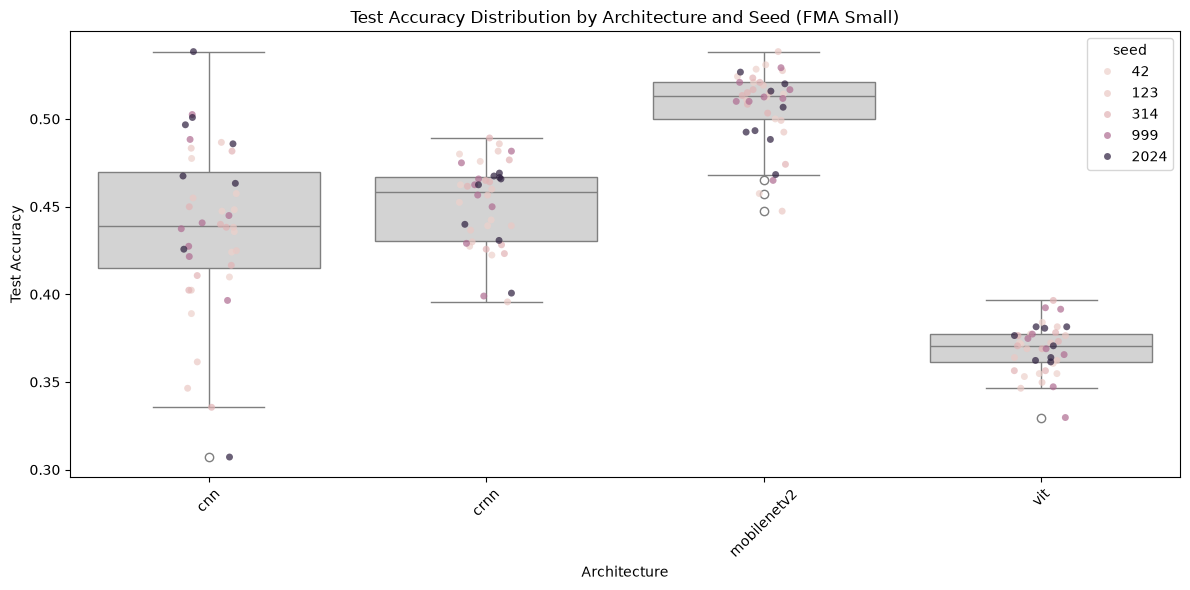

In [121]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=run_summaries_df,
    x="model",
    y="test_accuracy",
    color="lightgray"
)

sns.stripplot(
    data=run_summaries_df,
    x="model",
    y="test_accuracy",
    hue="seed",
    dodge=False,
    alpha=0.7,
    size=5
)

plt.ylabel("Test Accuracy")
plt.xlabel("Architecture")

plt.title(
    "Test Accuracy Distribution by Architecture and Seed (FMA Small)"
)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Comments 
Classification performance varied across architectures, although the spread of the distributions was smaller than that observed in the GTZAN experiments. MobileNetV2 produced the highest mean test accuracy (0.508) and exhibited a relatively narrow distribution centered around approximately 0.50–0.53 across durations and seeds, indicating consistent performance under varying experimental conditions. CRNN achieved the second-highest mean accuracy (0.451) and displayed moderate variability across runs. CNN achieved a mean accuracy of 0.438, but its distribution contained several lower-performing runs near 0.31–0.35, contributing to a wider spread than MobileNetV2. ViT produced the lowest mean accuracy (0.369) and a comparatively compact distribution centered around 0.35–0.39.

The distribution widths suggest that model stability differed across architectures. MobileNetV2 showed both the highest central tendency and one of the tightest distributions, whereas CNN and CRNN exhibited greater variation across random seeds and duration conditions. The consistency of the MobileNetV2 results supports the generalization findings reported later, where MobileNetV2 also demonstrated the smallest average generalization gap (0.074) and no observed overfitting events.


## Table 4. Model Efficiency Ranking

In [122]:
model_efficiency_table = (
    model_efficiency_df[
        [
            "model",
            "params_million",
            "mean_accuracy",
            "mean_accuracy_per_million",
            "mean_training_seconds"
        ]
    ]
    .copy()
)

model_efficiency_table.columns = [
    "Architecture",
    "Parameters (M)",
    "Accuracy",
    "Accuracy / Million Params",
    "Training Seconds"
]

display_table(
    model_efficiency_table
)

Architecture,Parameters (M),Accuracy,Accuracy / Million Params,Training Seconds
cnn,0.1292,0.4377,3.3869,211.7753
crnn,0.3451,0.4511,1.3071,235.1405
mobilenetv2,2.5880,0.5075,0.1961,291.2290
vit,1.4207,0.3688,0.2596,1016.0493


### Comments
Model efficiency varied substantially across architectures. CNN achieved the highest parameter efficiency, producing 0.438 accuracy with only 0.129 million parameters, corresponding to 3.387 accuracy per million parameters. CRNN achieved the second-highest efficiency, producing 0.451 accuracy with 0.345 million parameters, corresponding to 1.307 accuracy per million parameters. In contrast, MobileNetV2 achieved the highest overall classification accuracy (0.508) but required 2.588 million parameters, resulting in a lower efficiency score (0.196 accuracy per million parameters).

Training time also varied considerably. CNN completed training in approximately 212 seconds, while CRNN required 235 seconds and MobileNetV2 required 291 seconds. ViT exhibited the highest computational cost, requiring approximately 1,016 seconds of training time while producing the lowest overall accuracy (0.369) among the evaluated architectures.

These results demonstrate that predictive performance and computational efficiency represent distinct dimensions of model evaluation. MobileNetV2 achieved the strongest overall classification results (0.508 accuracy, 0.499 F1), whereas CNN achieved the strongest parameter efficiency (3.387 accuracy per million parameters). Consequently, the architecture producing the highest classification performance was not the architecture producing the greatest performance relative to model size or training cost.


## Figure 3. Generalization Gap by Architecture

Text(0.5, 1.0, 'Generalization Gap by Architecture (FMA Small)')

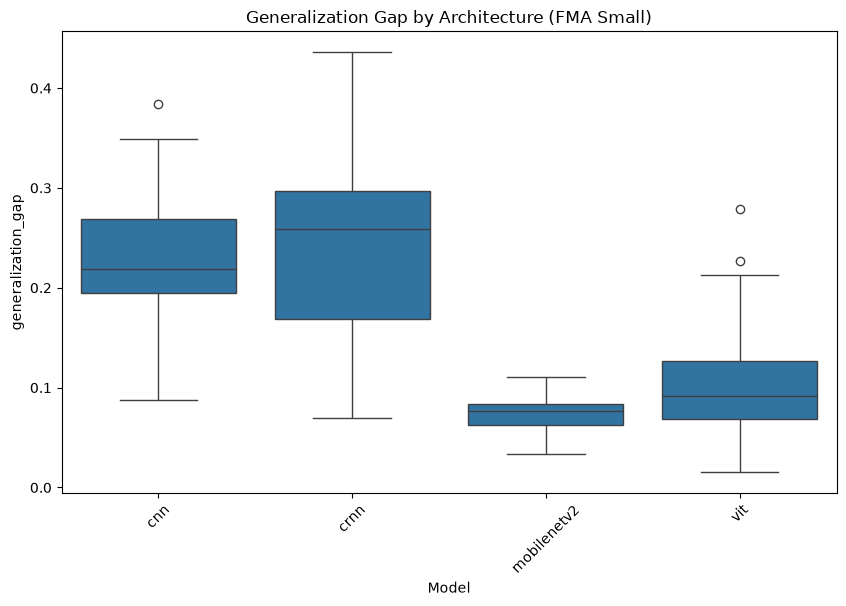

In [123]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=run_summaries_df,
    x="model",
    y="generalization_gap"
)

plt.xlabel("Generalization Gap")
plt.xlabel("Model")

plt.xticks(rotation=45)
plt.title("Generalization Gap by Architecture (FMA Small)")

### Comments 
Generalization behavior varied considerably across architectures. MobileNetV2 exhibited the smallest mean generalization gap (0.074) and no observed overfitting events (0.000 overfitting rate), indicating the strongest agreement between training and evaluation performance. ViT produced the second-smallest mean gap (0.102) and a low overfitting rate (0.075), suggesting relatively stable behavior despite achieving the lowest overall classification accuracy. The distributions for both MobileNetV2 and ViT are concentrated within a relatively narrow range, indicating consistent generalization across durations and random seeds.

CNN and CRNN exhibited substantially larger generalization gaps. CNN produced a mean generalization gap of 0.231 and an overfitting rate of 0.725, while CRNN produced the largest mean gap (0.241) and an overfitting rate of 0.650. The wider distributions observed for these architectures indicate greater sensitivity to training conditions and a larger separation between training and evaluation performance.


## Table 5. Training Behavior Summary

In [124]:
training_behavior_table = (
    training_behavior_df
    .copy()
)

training_behavior_table.columns = [
    "Architecture",
    "Avg Best Epoch",
    "Convergence Speed",
    "Training Seconds",
    "Training Accuracy Gain",
    "Generalization Gap",
    "Absolute Gap",
    "Overfitting Rate"
]


display_table(
    training_behavior_table
)

Architecture,Avg Best Epoch,Convergence Speed,Training Seconds,Training Accuracy Gain,Generalization Gap,Absolute Gap,Overfitting Rate
cnn,10.4750,0.6519,211.7753,0.3133,0.2310,0.2310,0.7250
crnn,13.5500,0.7124,235.1405,0.3311,0.2410,0.2410,0.6500
mobilenetv2,20.6500,0.8193,291.2290,0.1252,0.0737,0.0737,0.0000
vit,14.0500,0.7254,1016.0493,0.1419,0.1017,0.1017,0.0750


### Comments
MobileNetV2 exhibited the strongest generalization behavior among the evaluated architectures, producing the smallest mean generalization gap (0.074) and an overfitting rate of 0.000. The architecture also achieved the highest overall classification accuracy (0.508), indicating that strong predictive performance was achieved without a corresponding increase in overfitting.

ViT produced the second-smallest mean generalization gap (0.102) and a low overfitting rate (0.075). However, its overall classification accuracy (0.369) remained substantially below the other evaluated architectures. This combination suggests that ViT generalized consistently but failed to achieve competitive predictive performance under the evaluated training conditions.


## Figure 4. Architecture Efficiency Landscape

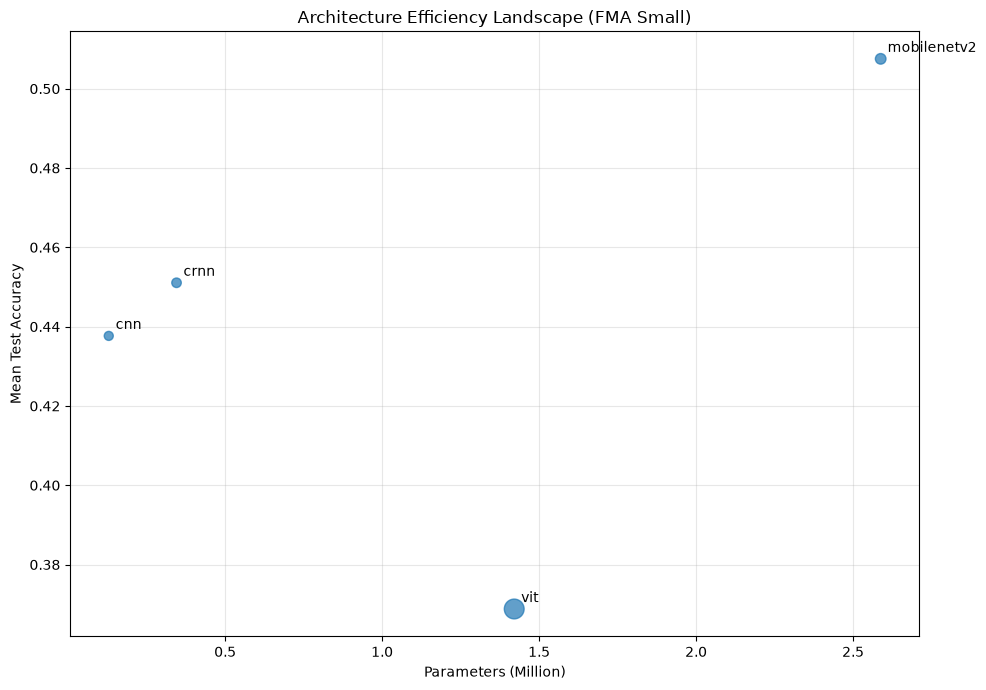

In [125]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    model_efficiency_df["params_million"],
    model_efficiency_df["mean_accuracy"],
    s=model_efficiency_df["mean_training_seconds"] / 5,
    alpha=0.7
)

for _, row in model_efficiency_df.iterrows():
    plt.annotate(
        row["model"],
        (
            row["params_million"],
            row["mean_accuracy"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Parameters (Million)")
plt.ylabel("Mean Test Accuracy")

plt.title(
    "Architecture Efficiency Landscape (FMA Small)"
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Comments
The architecture efficiency landscape reveals substantial variation in the relationship between model size, predictive performance, and computational cost. MobileNetV2 achieved the highest overall accuracy (0.508) but required 2.588 million parameters, making it the largest architecture evaluated. CNN achieved a lower overall accuracy (0.438) but required only 0.129 million parameters, resulting in the highest parameter efficiency (3.387 accuracy per million parameters) among the evaluated models.

CRNN occupied an intermediate position in the efficiency landscape, achieving 0.451 accuracy with 0.345 million parameters and an efficiency score of 1.307 accuracy per million parameters. Although MobileNetV2 outperformed CRNN in absolute classification accuracy, CRNN achieved competitive performance with approximately one-seventh the parameter count.

ViT represented the least efficient architecture under the evaluated conditions. Despite containing 1.421 million parameters and requiring approximately 1,016 seconds of training time, ViT achieved the lowest overall classification accuracy (0.369) and an efficiency score of only 0.260 accuracy per million parameters. This indicates that increased architectural complexity and training cost did not necessarily translate into improved classification performance.

Collectively, these results demonstrate that model size alone was not a reliable predictor of classification effectiveness. MobileNetV2 achieved the strongest predictive performance, whereas CNN achieved the strongest parameter efficiency, indicating that predictive accuracy and computational efficiency represent distinct dimensions of model evaluation.


# 4. Duration Effects

## Figure 5. Accuracy as a Function of Audio Duration

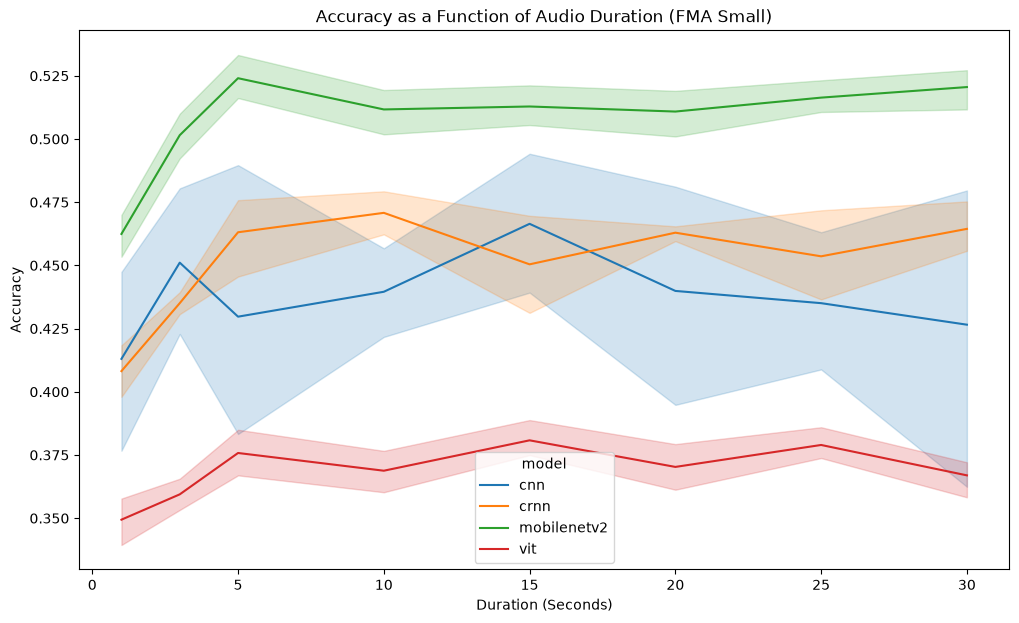

In [126]:
plt.figure(figsize=(12,7))

sns.lineplot(
    data=run_summaries_df,
    x="duration_seconds",
    y="test_accuracy",
    hue="model",
    estimator="mean",
    errorbar=("ci",95)
)

plt.ylabel("Accuracy")
plt.xlabel("Duration (Seconds)")

plt.title(
    "Accuracy as a Function of Audio Duration (FMA Small)"
)

plt.show()

### Comments
Mean classification accuracy generally increased between 1-second and 5-second excerpts across the evaluated architectures. MobileNetV2 improved from approximately 0.462 accuracy at 1 second to 0.524 at 5 seconds, while CRNN improved from approximately 0.409 to 0.463 over the same interval. CNN increased from approximately 0.413 to 0.430, and ViT increased from approximately 0.349 to 0.375. These early gains indicate that a substantial portion of the information required for genre classification becomes available within the first few seconds of audio.

Beyond approximately 5 to 10 seconds, additional increases in clip duration produced comparatively small changes in performance for most architectures. MobileNetV2 remained relatively stable between approximately 0.51 and 0.52 accuracy from 10 seconds through 30 seconds, while CRNN remained near 0.45–0.47 accuracy over the same interval. CNN and ViT similarly exhibited only modest fluctuations after the initial increase observed at shorter durations.

Architecture rankings remained consistent throughout the duration range. MobileNetV2 maintained the highest accuracy across all evaluated clip lengths, while ViT produced the lowest performance throughout the study. CNN and CRNN occupied an intermediate performance tier, with CRNN generally outperforming CNN at longer durations.

The performance distributions further indicate that variability across seeds persisted throughout the duration range. CNN displayed the largest uncertainty bands, particularly at shorter durations, whereas MobileNetV2 exhibited comparatively narrow confidence intervals across most durations. These results suggest that clip duration influenced both predictive performance and model stability, although the magnitude of the effect differed across architectures.


## Figure 6. Accuracy Gain by Duration Increment

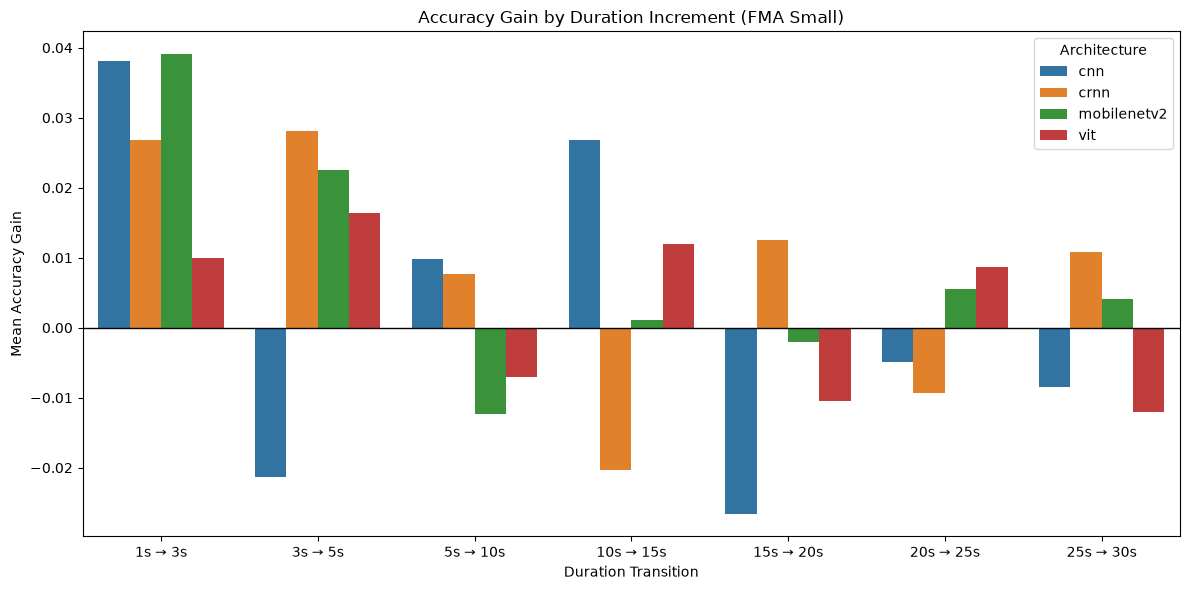

In [127]:
duration_pairwise_df["End Duration"] = (
    duration_pairwise_df["Comparison"]
    .str.extract(
        r"→\s*(\d+)s"
    )
    .astype(int)
)
plt.figure(
    figsize=(12, 6)
)

sns.barplot(
    data=duration_pairwise_df,
    x="Comparison",
    y="Mean Gain",
    hue="Architecture"
)

plt.axhline(
    0,
    color="black",
    linewidth=1
)

plt.title(
    "Accuracy Gain by Duration Increment (FMA Small)"
)

plt.xlabel(
    "Duration Transition"
)

plt.ylabel(
    "Mean Accuracy Gain"
)

plt.tight_layout()

plt.show()

### Comments
The largest accuracy gains occurred during the earliest duration transitions across all evaluated architectures. MobileNetV2 improved by approximately 0.039 accuracy when moving from 1-second to 3-second excerpts, while CNN improved by approximately 0.038 and CRNN improved by approximately 0.027 over the same interval. ViT exhibited the smallest early gain (0.010), but still achieved its largest positive improvement during the first duration transition.

Beyond the 1-second to 5-second range, the magnitude of the duration increments decreased substantially. Most subsequent duration transitions produced gains smaller than 0.02 accuracy, and several transitions resulted in small negative changes. For example, MobileNetV2 decreased slightly between 5s and 10s (-0.012) and between 15s and 20s (-0.002), while CNN exhibited alternating positive and negative changes throughout the longer durations.

The duration-gain profiles differed across architectures. MobileNetV2 and CRNN showed the largest overall improvements from increasing clip length, whereas CNN and ViT exhibited comparatively small net gains. Despite these differences, all architectures demonstrated the same broad pattern: the greatest improvement occurred when increasing beyond the shortest excerpts, while later increases in duration produced progressively smaller changes in classification performance.

Taken together, the figure provides evidence that the relationship between duration and performance is non-linear. Additional listening time remained beneficial for some architectures, but the largest gains were concentrated in the earliest duration increases rather than being distributed uniformly across the duration range.


## Table 6. Duration Performance Summary

In [128]:
duration_performance_table = (
    duration_performance_df[
        [
            "duration_seconds",
            "mean_accuracy",
            "mean_f1",
            "mean_precision",
            "mean_recall",
            "accuracy_ci95_lower",
            "accuracy_ci95_upper"
        ]
    ]
    .copy()
)

duration_performance_table.columns = [
    "Duration (s)",
    "Accuracy",
    "F1",
    "Precision",
    "Recall",
    "CI Lower",
    "CI Upper"
]

display_table(
    duration_performance_table
)

Duration (s),Accuracy,F1,Precision,Recall,CI Lower,CI Upper
1,0.4083,0.3940,0.4168,0.4084,0.3874,0.4292
3,0.4368,0.4219,0.4468,0.4369,0.4126,0.4609
5,0.4482,0.4316,0.4609,0.4484,0.4201,0.4763
10,0.4477,0.4323,0.4613,0.4478,0.4235,0.4720
15,0.4526,0.4370,0.4588,0.4528,0.4296,0.4757
20,0.4460,0.4327,0.4559,0.4461,0.4202,0.4718
25,0.4460,0.4292,0.4679,0.4461,0.4223,0.4697
30,0.4446,0.4241,0.4518,0.4448,0.4150,0.4742


### Comments
Mean classification accuracy increased from 0.408 at 1 second to 0.437 at 3 seconds, representing the largest improvement observed across adjacent duration levels (+0.029 accuracy). Accuracy continued increasing to 0.448 at 5 seconds and reached a maximum mean value of 0.453 at 15 seconds. Similar patterns were observed for F1 score, which increased from 0.394 at 1 second to 0.432 at 5 seconds, and precision, which increased from 0.417 at 1 second to 0.461 at 10 seconds.

The largest gains occurred during the earliest duration transitions. Accuracy increased by approximately 0.029 between 1 and 3 seconds and by 0.011 between 3 and 5 seconds. Beyond 5 seconds, average performance remained relatively stable. Mean accuracy ranged from 0.445 to 0.453 across all durations from 10 to 30 seconds, while F1 scores remained within a similarly narrow range (0.424–0.437).

The confidence intervals support this pattern. The 1-second condition produced a mean accuracy confidence interval of [0.387, 0.429], while durations from 5 to 30 seconds produced heavily overlapping confidence intervals centered near 0.44–0.45 accuracy. For example, the confidence intervals for 5 seconds ([0.420, 0.476]) and 30 seconds ([0.415, 0.474]) are nearly identical.

These results suggest that a substantial portion of the information required for genre classification became available within the first several seconds of audio. Additional listening context beyond approximately 5 to 10 seconds produced comparatively small improvements, indicating a non-linear relationship characterized by diminishing returns and an earlier performance plateau than might be expected from a simple linear duration-performance relationship.


## Figure 7. Test Accuracy by Audio Duration

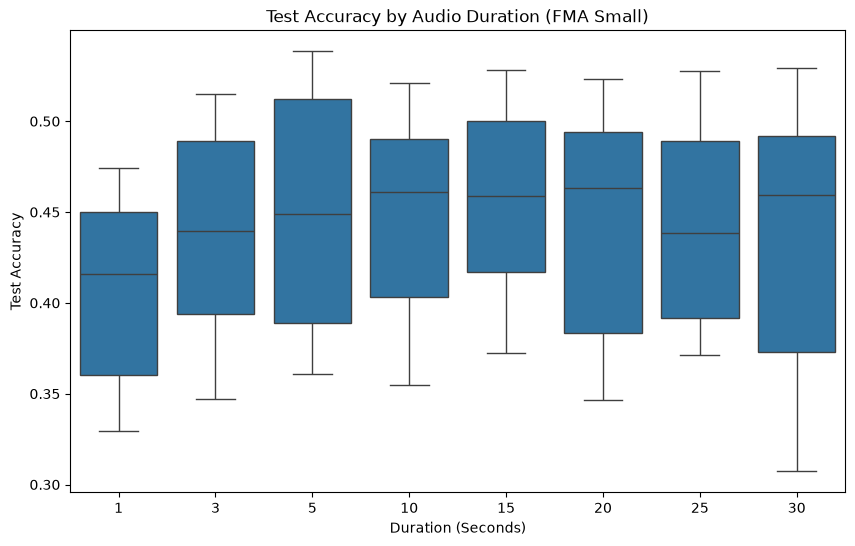

In [129]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=run_summaries_df,
    x="duration_seconds",
    y="test_accuracy"
)

plt.title(
    "Test Accuracy by Audio Duration (FMA Small)"
)

plt.xlabel("Duration (Seconds)")
plt.ylabel("Test Accuracy")

plt.show()

### Comments
The distribution of test accuracy shifted upward between 1-second and 5-second excerpts. The median accuracy increased from approximately 0.41 at 1 second to approximately 0.45 at 5 seconds, while the upper portion of the distribution moved from approximately 0.45 to above 0.50. These shifts indicate that the largest duration-related improvements occurred during the earliest increases in available listening context.

Beyond 5 seconds, the distributions remained comparatively stable. Median test accuracy generally remained within the 0.44–0.46 range for durations between 10 and 30 seconds, and the upper quartiles exhibited only modest changes. This pattern is consistent with the mean-duration analysis, which showed relatively small differences among durations longer than five seconds.

Variability persisted across all duration conditions. The 1-second distribution exhibited the widest relative spread, with accuracy values ranging from approximately 0.33 to 0.47. Although variability remained visible at longer durations, the distributions became more concentrated around their median values, suggesting that longer excerpts contributed to more consistent performance across architectures and random seeds.

Overall, the boxplots reinforce the conclusion that additional listening context improved classification performance, particularly when increasing from the shortest excerpts. However, the magnitude of improvement diminished substantially at longer durations, with the distributions suggesting an effective performance plateau emerging between approximately 5 and 10 seconds.


## Table 7. Duration Rankings

In [130]:
duration_rankings_table = (
    model_duration_rankings_df[
        [
            "duration_seconds",
            "model",
            "mean_accuracy",
            "mean_test_f1",
            "accuracy_rank",
            "f1_rank",
            "mean_rank"
        ]
    ]
    .copy()
)

duration_rankings_table.columns = [
    "Duration (s)",
    "Architecture",
    "Accuracy",
    "F1",
    "Accuracy Rank",
    "F1 Rank",
    "Composite Rank"
]

duration_rankings_table

,Duration (s),Architecture,Accuracy,F1,Accuracy Rank,F1 Rank,Composite Rank
0,1,mobilenetv2,0.462437,0.453413,1.0,1.0,1.0
1,1,cnn,0.413022,0.393520,2.0,3.0,2.5
2,1,crnn,0.408180,0.394233,3.0,2.0,2.5
3,1,vit,0.349416,0.334920,4.0,4.0,4.0
4,3,mobilenetv2,0.501503,0.492338,1.0,1.0,1.0
5,3,cnn,0.451085,0.430750,2.0,2.0,2.0
6,3,crnn,0.435058,0.424261,3.0,3.0,3.0
7,3,vit,0.359432,0.340107,4.0,4.0,4.0
8,5,mobilenetv2,0.524040,0.514878,1.0,1.0,1.0
9,5,crnn,0.463105,0.452175,2.0,2.0,2.0


### Comments
Architecture rankings remained remarkably consistent across audio durations. At 1 second, MobileNetV2 achieved the highest classification accuracy (0.462) and F1 score (0.453), giving it the strongest composite rank (1.0). CNN (0.413 accuracy) and CRNN (0.408 accuracy) occupied the middle positions, while ViT ranked last with 0.349 accuracy and 0.335 F1.

The ranking structure remained unchanged as duration increased. At 3 seconds, MobileNetV2 retained the highest accuracy (0.502) and F1 score (0.492), followed by CNN (0.451 accuracy, 0.431 F1), CRNN (0.435 accuracy, 0.424 F1), and ViT (0.359 accuracy, 0.340 F1). At 5 seconds, MobileNetV2 again maintained first place (0.524 accuracy, 0.515 F1), with CRNN moving slightly ahead of CNN but all three non-transformer architectures retaining the same general ordering.



## Table 8. Statistical Significance of Duration Effects

In [131]:
duration_significance_table[
    "Mean Accuracy Gain (%)"
] = (
    duration_significance_table[
        "Mean Accuracy Gain"
    ]
    * 100
)

duration_significance_table = (
    duration_significance_table[
        [
            "Architecture",
            "Mean Accuracy Gain (%)",
            "t Statistic",
            "p Value",
            "Cohen's d",
            "Significant (p < .05)"
        ]
    ]
)

display_table(duration_significance_table)

Architecture,Mean Accuracy Gain (%),t Statistic,p Value,Cohen's d,Significant (p < .05)
mobilenetv2,5.8097,7.7115,0.0015,3.4487,True
crnn,5.6260,5.5187,0.0053,2.4680,True
vit,1.7529,2.8711,0.0454,1.2840,True
cnn,1.3523,0.3093,0.7725,0.1383,False


### Comments
The largest accuracy gains occurred during the earliest duration transitions for all evaluated architectures. MobileNetV2 (+0.039), CNN (+0.038), and CRNN (+0.027) achieved their greatest improvements between 1-second and 3-second excerpts. Subsequent duration transitions generally produced gains smaller than 0.02 accuracy, and several transitions resulted in small negative changes. MobileNetV2 and CRNN exhibited the largest overall duration sensitivity, whereas CNN and ViT demonstrated comparatively small net gains. The results indicate that most duration-related benefits were realized within the first five seconds of audio, with later increases producing relatively small changes in predictive performance.


# 5. Genre-Level Analysis

## Figure 8. Genre Sensitivity to Additional Audio Duration

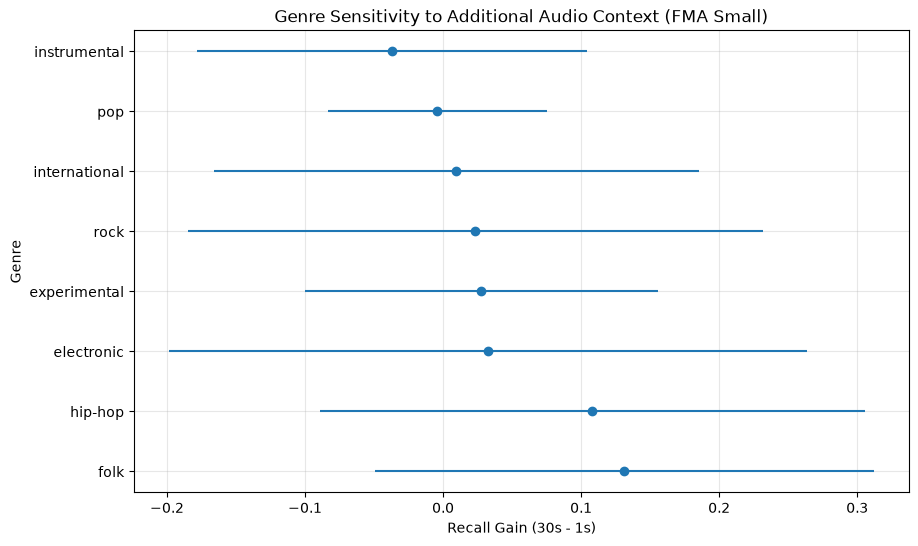

In [132]:
genre_plot = (
    duration_recall_gain_summary_df
    .groupby("genre")
    .agg(
        gain=("mean_gain", "mean"),
        lower=("lower_ci", "mean"),
        upper=("upper_ci", "mean")
    )
    .reset_index()
)

genre_plot = genre_plot.sort_values(
    "gain",
    ascending=False
)

plt.figure(figsize=(10,6))

plt.errorbar(
    x=genre_plot["gain"],
    y=genre_plot["genre"],
    xerr=[
        genre_plot["gain"] - genre_plot["lower"],
        genre_plot["upper"] - genre_plot["gain"]
    ],
    fmt="o"
)

plt.xlabel(
    "Recall Gain (30s - 1s)"
)

plt.ylabel("Genre")

plt.title(
    "Genre Sensitivity to Additional Audio Context (FMA Small)"
)

plt.grid(alpha=0.3)

plt.show()

### Comments
Genre sensitivity to additional listening context varied substantially across the FMA Small dataset. Folk exhibited the largest recall improvement, increasing from 0.444 recall at 1 second to 0.575 recall at 30 seconds, representing an absolute gain of 0.131 recall. Hip-Hop exhibited the second-largest improvement, increasing from 0.477 to 0.585 recall, for a gain of 0.108 recall. These two genres produced the strongest positive duration effects observed in the dataset.

Several genres exhibited only modest duration-related improvements. Electronic increased from 0.458 to 0.490 recall (+0.033), Experimental increased from 0.309 to 0.337 (+0.028), and Rock increased from 0.545 to 0.568 (+0.023). International exhibited only a small gain (+0.010) despite substantial increases in available listening context.

Not all genres benefited from longer excerpts. Pop recall decreased slightly from 0.122 at 1 second to 0.117 at 30 seconds (−0.004), while Instrumental decreased from 0.476 to 0.439 recall (−0.037). The confidence intervals associated with these genres include zero, indicating that the observed changes were not statistically supported.

Overall, the figure demonstrates that duration effects were highly genre dependent. The largest gains were concentrated in Folk and Hip-Hop, while several other genres exhibited only small improvements or no measurable benefit. These results suggest that additional audio context does not contribute equally across the genre taxonomy and that some genres contain substantially more duration-dependent information than others.


## Table 9. Genre Duration Sensitivity and Best Architecture

In [133]:
genre_seed_recall = []

for (
    model,
    seed,
    duration,
    genre
), group in (
    confusion_matrix_long_df.groupby(
        [
            "model",
            "seed",
            "duration",
            "actual"
        ]
    )
):

    total = group["count"].sum()

    correct = (
        group.loc[
            group["actual"]
            == group["predicted"],
            "count"
        ]
        .sum()
    )

    recall = (
        correct / total
        if total > 0
        else np.nan
    )

    genre_seed_recall.append({
        "model": model,
        "seed": seed,
        "duration": duration,
        "genre": genre,
        "recall": recall
    })

genre_seed_recall_df = pd.DataFrame(
    genre_seed_recall
)

# --------------------------------------------------
# Compute genre-level gains and confidence intervals
# --------------------------------------------------

research_records = []

for genre, group in (
    genre_seed_recall_df.groupby("genre")
):

    recall_1s = (
        group[
            group["duration"] == 1
        ]
        .sort_values(
            ["model", "seed"]
        )["recall"]
    )

    recall_30s = (
        group[
            group["duration"] == 30
        ]
        .sort_values(
            ["model", "seed"]
        )["recall"]
    )

    gains = (
        recall_30s.values
        - recall_1s.values
    )

    mean_gain = gains.mean()

    n = len(gains)
    std_gain = gains.std(ddof=1)

    sem = std_gain / np.sqrt(n)

    ci95 = (
        t.ppf(
            0.975,
            df=n - 1
        )
        * sem
    )

    recall_1_mean = recall_1s.mean()
    recall_30_mean = recall_30s.mean()

    relative_gain = (
        100
        * (
            recall_30_mean
            - recall_1_mean
        )
        / recall_1_mean
    )

    ci_lower = mean_gain - ci95
    ci_upper = mean_gain + ci95

    research_records.append({
        "Genre": genre,
        "Recall @ 1s": recall_1_mean,
        "Recall @ 30s": recall_30_mean,
        "Recall Gain": mean_gain,
        "Relative Recall Gain (%)": relative_gain,
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper,
        "Significant": (
            "Yes"
            if ci_lower > 0
            else "No"
        )
    })

gain_stats_df = pd.DataFrame(
    research_records
)

# --------------------------------------------------
# Best architecture for each genre
# --------------------------------------------------

best_architecture_df = (
    genre_recall_by_model_df
    .sort_values(
        "recall",
        ascending=False
    )
    .groupby("genre")
    .first()
    .reset_index()
)

best_architecture_df = (
    best_architecture_df[
        [
            "genre",
            "model",
            "recall"
        ]
    ]
)

best_architecture_df.columns = [
    "Genre",
    "Best Architecture",
    "Best Recall"
]

# --------------------------------------------------
# Final research question table
# --------------------------------------------------

research_question_table = (
    gain_stats_df
    .merge(
        best_architecture_df,
        on="Genre"
    )
    .sort_values(
        "Relative Recall Gain (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

research_question_table = (
    research_question_table[
        [
            "Genre",
            "Recall @ 1s",
            "Recall @ 30s",
            "Recall Gain",
            "Relative Recall Gain (%)",
            "95% CI Lower",
            "95% CI Upper",
            "Significant",
            "Best Architecture",
            "Best Recall"
        ]
    ]
)

display_table(research_question_table)

Genre,Recall @ 1s,Recall @ 30s,Recall Gain,Relative Recall Gain (%),95% CI Lower,95% CI Upper,Significant,Best Architecture,Best Recall
folk,0.4437,0.5750,0.1313,29.6018,0.0486,0.2140,Yes,mobilenetv2,0.6010
hip-hop,0.4765,0.5846,0.1081,22.6761,0.0178,0.1983,Yes,mobilenetv2,0.6394
experimental,0.3093,0.3370,0.0277,8.9440,-0.0238,0.0791,No,mobilenetv2,0.4152
electronic,0.4577,0.4903,0.0326,7.1114,-0.0709,0.1360,No,mobilenetv2,0.5512
rock,0.5450,0.5683,0.0233,4.2813,-0.0637,0.1104,No,crnn,0.5780
international,0.4370,0.4467,0.0097,2.2121,-0.0836,0.1030,No,mobilenetv2,0.5672
pop,0.1217,0.1173,-0.0043,-3.5616,-0.0337,0.0251,No,mobilenetv2,0.1985
instrumental,0.4760,0.4390,-0.0370,-7.7731,-0.1058,0.0318,No,mobilenetv2,0.5192


### Comments
Genre sensitivity to additional listening context varied substantially across the FMA Small dataset. Folk exhibited the largest recall improvement, increasing from 0.444 recall at 1 second to 0.575 recall at 30 seconds, representing an absolute gain of 0.131 recall. Hip-Hop exhibited the second-largest improvement, increasing from 0.477 to 0.585 recall, for a gain of 0.108 recall. These two genres produced the strongest positive duration effects observed in the dataset.

Several genres exhibited only modest duration-related improvements. Electronic increased from 0.458 to 0.490 recall (+0.033), Experimental increased from 0.309 to 0.337 (+0.028), and Rock increased from 0.545 to 0.568 (+0.023). International exhibited only a small gain (+0.010) despite substantial increases in available listening context.

Not all genres benefited from longer excerpts. Pop recall decreased slightly from 0.122 at 1 second to 0.117 at 30 seconds (−0.004), while Instrumental decreased from 0.476 to 0.439 recall (−0.037). The confidence intervals associated with these genres include zero, indicating that the observed changes were not statistically supported.

Overall, the figure demonstrates that duration effects were highly genre dependent. The largest gains were concentrated in Folk and Hip-Hop, while several other genres exhibited only small improvements or no measurable benefit. These results suggest that additional audio context does not contribute equally across the genre taxonomy and that some genres contain substantially more duration-dependent information than others.


## Figure 9. Genre Recall Profile by Architecture

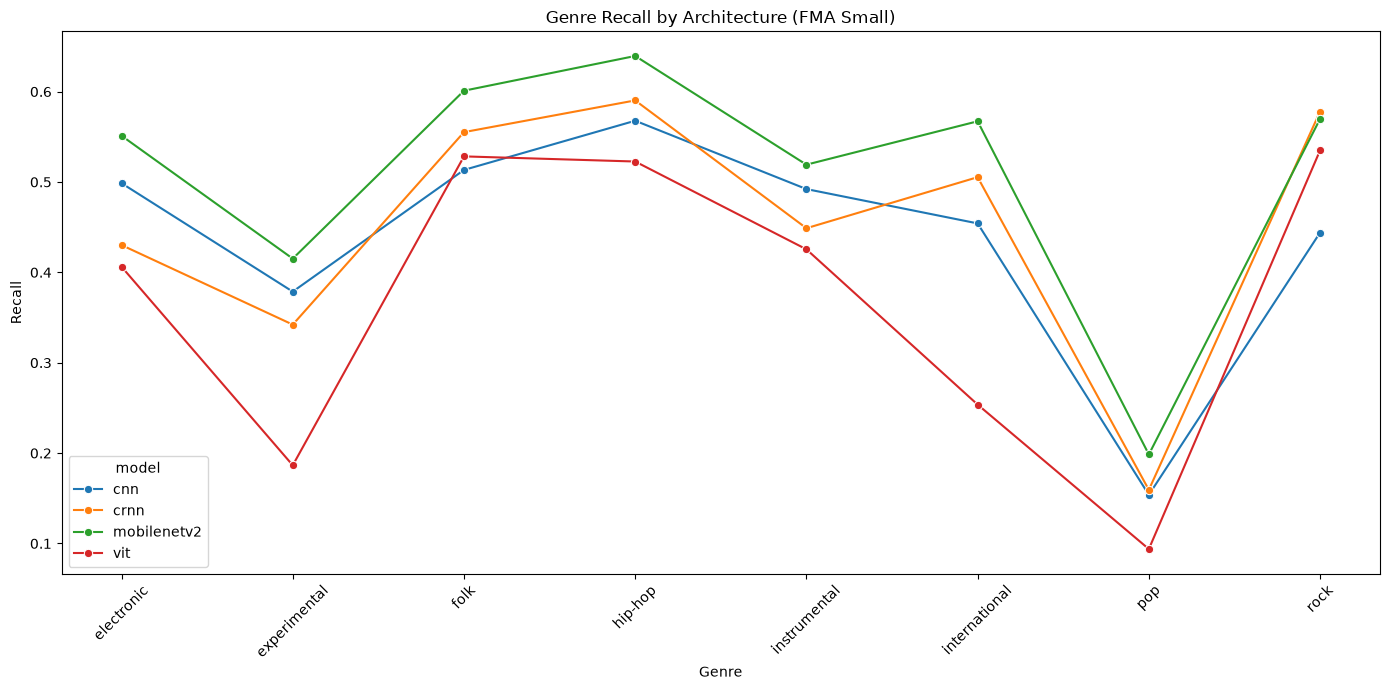

In [134]:
plt.figure(figsize=(14, 7))

genre_means = (
    genre_duration_recall_df
    .groupby(
        ["genre", "model"]
    )["recall"]
    .mean()
    .reset_index()
)

sns.lineplot(
    data=genre_means,
    x="genre",
    y="recall",
    hue="model",
    marker="o"
)

plt.title(
    "Genre Recall by Architecture (FMA Small)"
)

plt.xlabel("Genre")
plt.ylabel("Recall")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Comments
Genre recall varied considerably across the FMA Small genre taxonomy. Hip-Hop achieved the highest average recall across architectures, ranging from approximately 0.52 for ViT to 0.64 for MobileNetV2. Folk also produced consistently strong recall values across all models, ranging from approximately 0.51 to 0.60. In contrast, Pop exhibited the lowest recall across architectures, ranging from approximately 0.09 for ViT to 0.20 for MobileNetV2.

MobileNetV2 achieved the highest recall for most genres, including Electronic (0.551), Experimental (0.415), Folk (0.601), Hip-Hop (0.639), Instrumental (0.519), International (0.567), and Pop (0.199). Rock was the only genre for which CRNN achieved the highest recall (0.578). CNN generally occupied an intermediate position, while ViT consistently produced the lowest recall values across most genres.

The results indicate that architecture performance differed substantially by genre. MobileNetV2 exhibited broad strengths across the genre taxonomy, whereas CRNN demonstrated particular effectiveness for Rock. Pop remained difficult to classify regardless of architecture, suggesting that the low recall values were driven by the underlying genre structure rather than by deficiencies in any single model.


## Table 10. Genre Recall Summary by Architecture

In [135]:
genre_recall_summary_table = (
    genre_recall_by_model_df
    .pivot(
        index="genre",
        columns="model",
        values="recall"
    )
    .round(3)
)

display_table(genre_recall_summary_table)

cnn,crnn,mobilenetv2,vit
0.4990,0.4300,0.5510,0.4060
0.3790,0.3420,0.4150,0.1860
0.5130,0.5550,0.6010,0.5280
0.5680,0.5900,0.6390,0.5230
0.4920,0.4490,0.5190,0.4260
0.4540,0.5050,0.5670,0.2540
0.1540,0.1590,0.1980,0.0940
0.4440,0.5780,0.5700,0.5350


### Comments
Genre recall varied substantially across the FMA Small genre taxonomy. Hip-Hop achieved the highest mean recall across architectures, ranging from 0.523 for ViT to 0.639 for MobileNetV2. Folk also produced consistently strong performance, ranging from 0.513 for CNN to 0.601 for MobileNetV2. In contrast, Pop produced the lowest recall values across all evaluated architectures, ranging from 0.094 for ViT to 0.198 for MobileNetV2.

MobileNetV2 achieved the highest recall for seven of the eight evaluated genres, including Electronic (0.551), Experimental (0.415), Folk (0.601), Hip-Hop (0.639), Instrumental (0.519), International (0.567), and Pop (0.198). CRNN achieved the highest recall only for Rock (0.578), narrowly exceeding MobileNetV2 (0.570).

The figure demonstrates a clearer hierarchy among architectures than was observed on GTZAN. MobileNetV2 consistently produced the strongest genre-level performance, whereas ViT consistently produced the lowest recall values across most genres. Pop remained difficult regardless of architecture, suggesting that the challenge is driven more by genre overlap than by any specific modeling approach.


## Table 11. Average Genre Recall Ranking

In [136]:
genre_recall_ranking_table = (
    genre_recall_by_model_df
    .groupby("genre")["recall"]
    .agg(
        mean_recall="mean",
        std_recall="std",
        min_recall="min",
        max_recall="max"
    )
    .reset_index()
    .sort_values(
        "mean_recall",
        ascending=False
    )
)

display_table(
    genre_recall_ranking_table
)

genre,mean_recall,std_recall,min_recall,max_recall
hip-hop,0.5800,0.0486,0.5227,0.6394
folk,0.5495,0.0385,0.5133,0.6010
rock,0.5317,0.0614,0.4440,0.5780
electronic,0.4716,0.0660,0.4062,0.5512
instrumental,0.4714,0.0421,0.4255,0.5192
international,0.4451,0.1357,0.2537,0.5672
experimental,0.3306,0.1006,0.1865,0.4152
pop,0.1514,0.0432,0.0938,0.1985


### Comments
Genre recall varied substantially across the FMA Small genre taxonomy. Hip-Hop achieved the highest mean recall (0.580), followed by Folk (0.550) and Rock (0.532). MobileNetV2 achieved the strongest performance for Hip-Hop (0.639 recall) and Folk (0.601 recall), while CRNN achieved the highest Rock recall (0.578).

Electronic (0.472), Instrumental (0.471), and International (0.445) occupied the middle tier of performance. Experimental (0.331) produced noticeably lower recall across all architectures, while Pop produced the lowest mean recall (0.151) and remained the most difficult genre in the dataset. Even the strongest-performing architecture achieved only 0.199 recall on Pop.

Genre variability also differed considerably. International exhibited the largest standard deviation (0.136) and the widest recall range (0.254–0.567), indicating substantial sensitivity to architecture choice. Folk exhibited comparatively low variability (0.039 standard deviation) while maintaining high recall, suggesting consistently strong recognition across architectures.


## Table 12. Average Genre Recall Ranking

In [137]:
genre_duration_recall_table = (
    genre_duration_recall_df
    .pivot_table(
        index="genre",
        columns="duration",
        values="recall",
        aggfunc="mean"
    )
    .round(3)
)

display_table(genre_duration_recall_table)

1,3,5,10,15,20,25,30
0.4580,0.4460,0.5670,0.4450,0.4650,0.4490,0.4530,0.4900
0.3090,0.3150,0.3430,0.3580,0.3080,0.3770,0.2970,0.3370
0.4440,0.5460,0.5450,0.5710,0.5820,0.5720,0.5610,0.5750
0.4770,0.6160,0.5680,0.6160,0.6160,0.5790,0.5840,0.5850
0.4760,0.4450,0.4820,0.4760,0.5090,0.4740,0.4700,0.4390
0.4370,0.4610,0.4250,0.4330,0.4680,0.4140,0.4760,0.4470
0.1220,0.1510,0.1410,0.1570,0.1440,0.1860,0.1930,0.1170
0.5450,0.5150,0.5150,0.5270,0.5290,0.5180,0.5360,0.5680


### Comments
Genre recall trajectories differed substantially across the FMA Small genre taxonomy. Hip-Hop exhibited the highest recall throughout the duration range, increasing from 0.477 recall at 1 second to 0.585 recall at 30 seconds, while Folk increased from 0.444 to 0.575 recall. These two genres demonstrated the strongest positive response to increasing clip duration.

Electronic, Experimental, Rock, and International exhibited comparatively modest improvements. Electronic increased from 0.458 to 0.490 recall, Experimental increased from 0.309 to 0.337 recall, and Rock increased from 0.545 to 0.568 recall. International remained relatively stable across durations, ending only slightly above its starting recall value.

Not all genres benefited from additional listening context. Pop decreased slightly from 0.122 recall at 1 second to 0.117 recall at 30 seconds, while Instrumental declined from 0.476 to 0.439 recall. Although these decreases were not statistically significant, they demonstrate that additional audio duration was not universally beneficial across the genre taxonomy.


## Table 13. Genre Improvement Summary

In [138]:
genre_improvement_table = (
    genre_duration_recall_df
    .groupby(
        ["genre", "duration"]
    )["recall"]
    .mean()
    .reset_index()
    .pivot(
        index="genre",
        columns="duration",
        values="recall"
    )
)

genre_improvement_table["gain_1s_to_30s"] = (
    genre_improvement_table[30]
    - genre_improvement_table[1]
)

genre_improvement_table = (
    genre_improvement_table
    .sort_values(
        "gain_1s_to_30s",
        ascending=False
    )
)

genre_improvement_table

duration,1,3,5,10,15,20,25,30,gain_1s_to_30s
genre,,,,,,,,,
folk,0.443667,0.545667,0.545000,0.571333,0.582000,0.571667,0.561333,0.575000,0.131333
hip-hop,0.476510,0.616443,0.567785,0.616107,0.616107,0.578859,0.583893,0.584564,0.108054
electronic,0.457718,0.445973,0.566779,0.444631,0.465436,0.448993,0.452685,0.490268,0.032550
experimental,0.309333,0.315333,0.343333,0.357667,0.308000,0.377000,0.297333,0.337000,0.027667
rock,0.545000,0.514667,0.515333,0.527333,0.529333,0.518000,0.535667,0.568333,0.023333
international,0.437000,0.461333,0.425000,0.433000,0.468000,0.414000,0.475667,0.446667,0.009667
pop,0.121667,0.150667,0.141333,0.156667,0.144333,0.186333,0.192667,0.117333,-0.004333
instrumental,0.476000,0.445333,0.482333,0.476000,0.509000,0.474000,0.469667,0.439000,-0.037000


### Comments
Duration sensitivity was highly concentrated among a small subset of genres. Folk exhibited the largest recall improvement, increasing from 0.444 recall at 1 second to 0.575 recall at 30 seconds (+0.131). Hip-Hop produced the second-largest gain, increasing from 0.477 to 0.585 recall (+0.108). These two genres accounted for the majority of the duration-related improvement observed across the FMA Small dataset.

Several genres exhibited only modest improvements despite substantially longer excerpts. Electronic increased from 0.458 to 0.490 recall (+0.033), Experimental increased from 0.309 to 0.337 recall (+0.028), and Rock increased from 0.545 to 0.568 recall (+0.023). International exhibited only a small gain (+0.010).

Not all genres benefited from longer listening windows. Pop decreased slightly from 0.122 recall at 1 second to 0.117 recall at 30 seconds (−0.004), while Instrumental decreased from 0.476 to 0.439 recall (−0.037). These results indicate that additional listening context was not uniformly beneficial across the genre taxonomy.


## Figure 10. Genre Recall by Architecture Across Duration

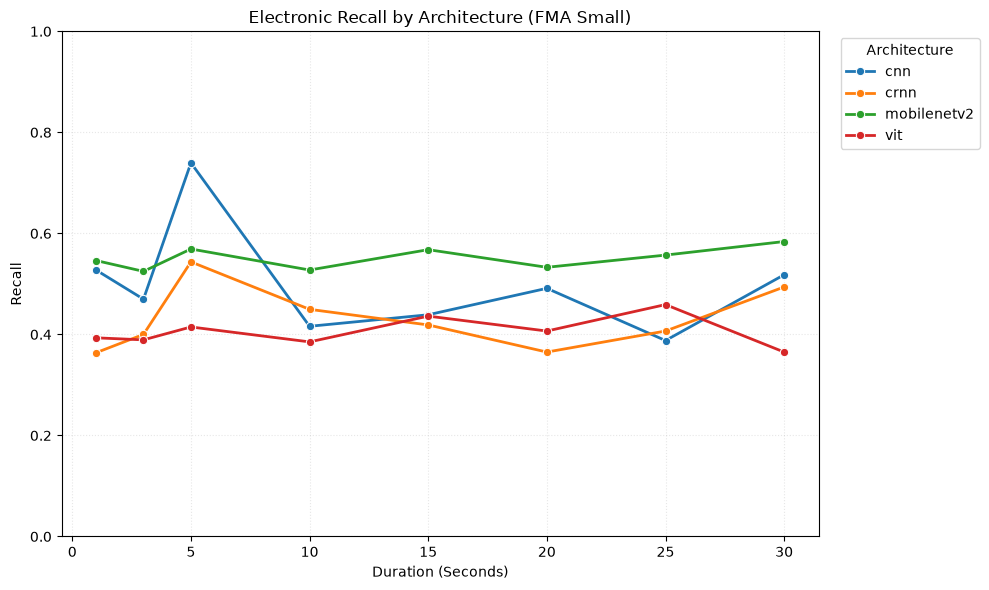

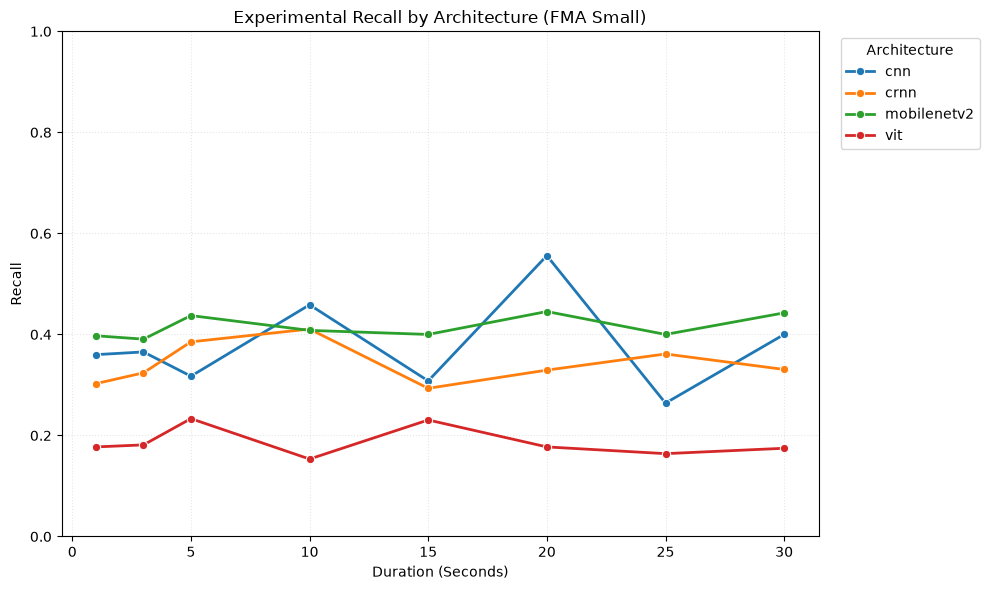

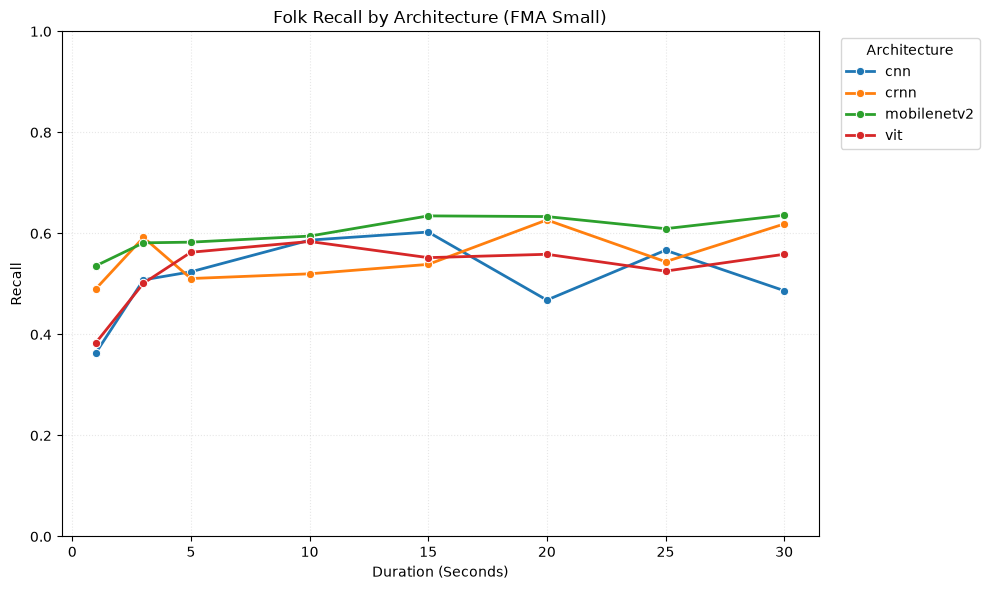

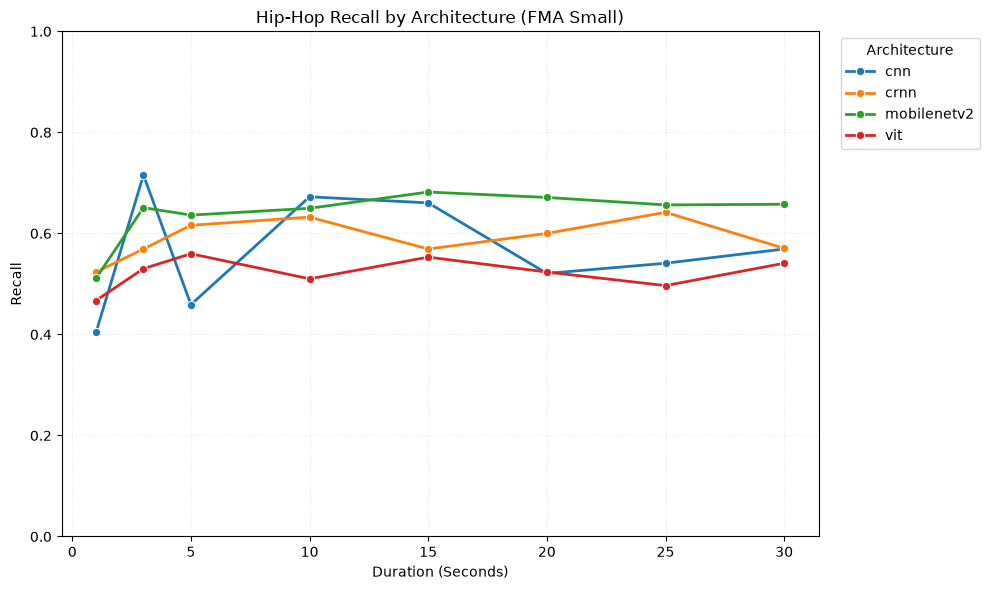

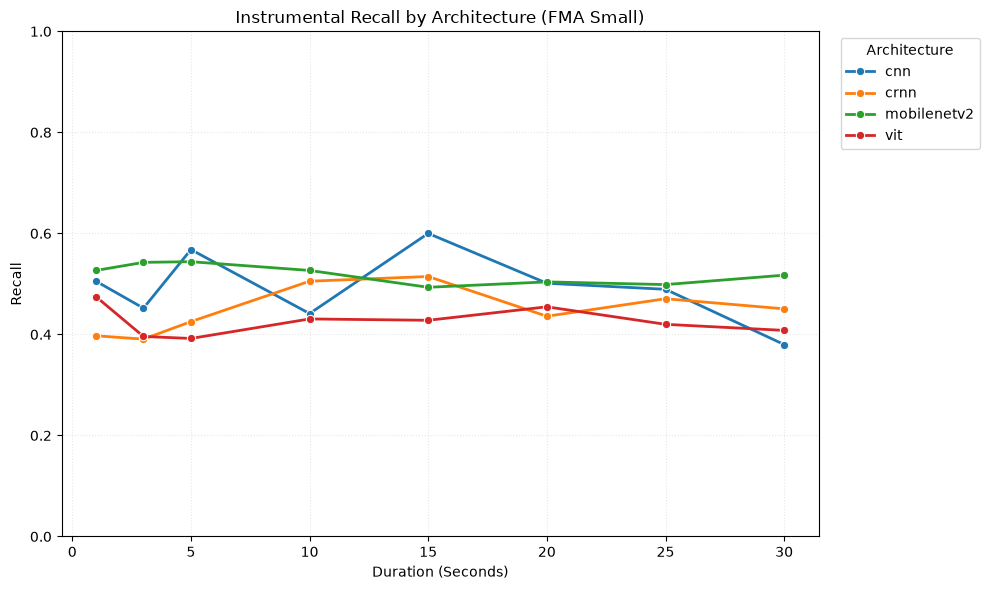

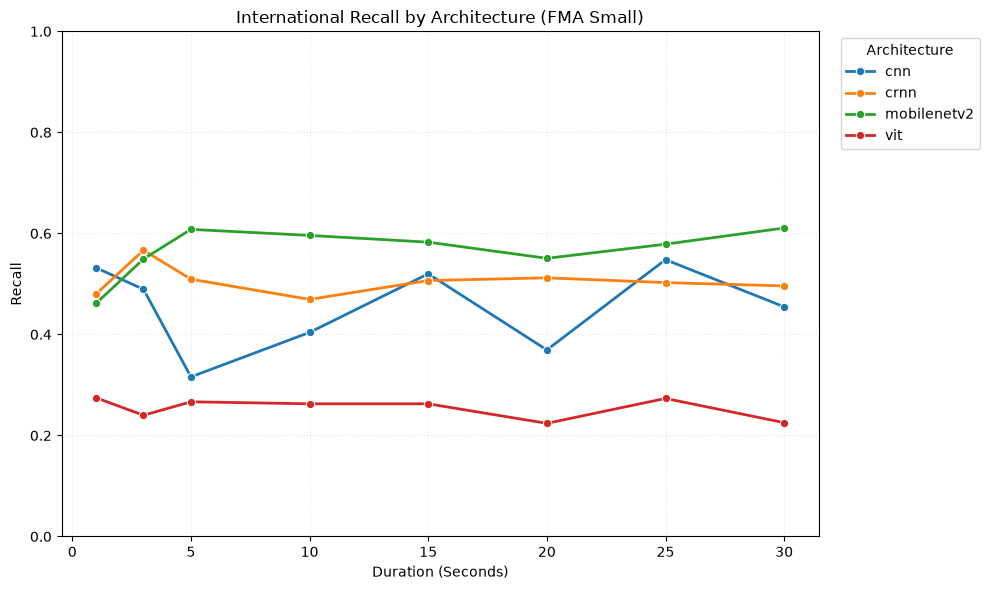

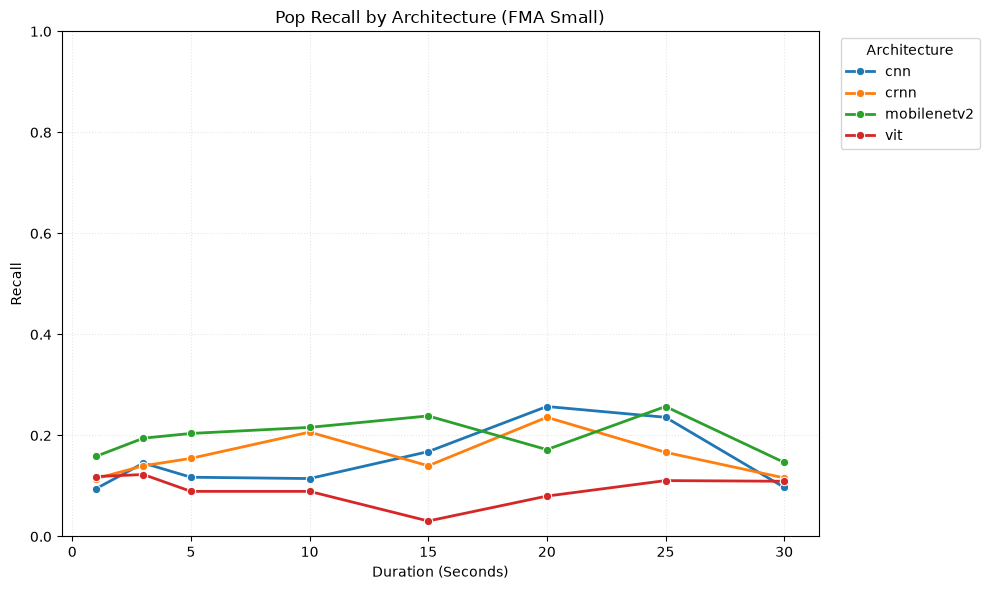

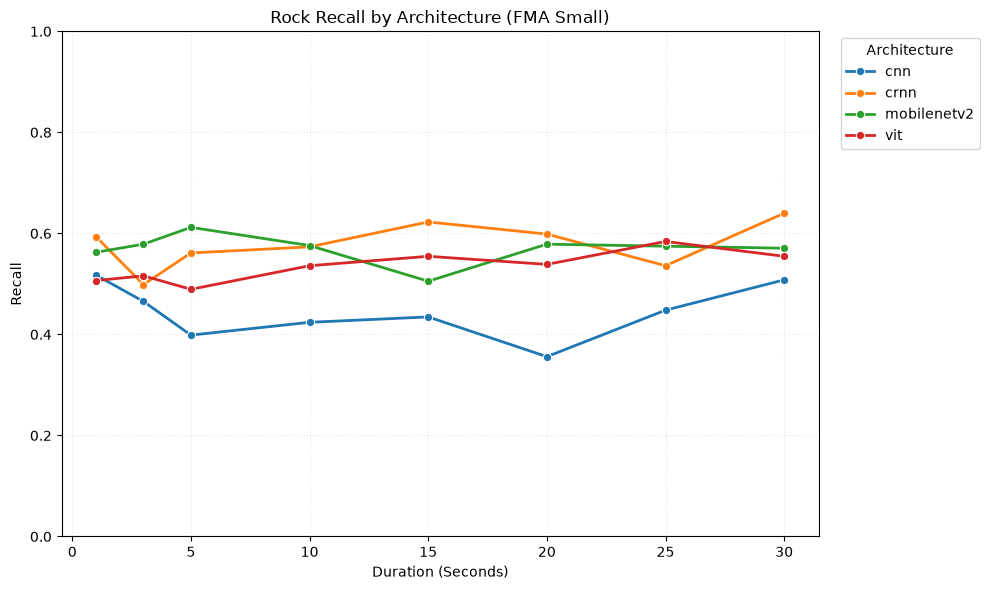

In [139]:
genres = sorted(
    genre_duration_recall_df["genre"].unique()
)

for genre in genres:

    plt.figure(figsize=(10, 6))

    subset = (
        genre_duration_recall_df[
            genre_duration_recall_df["genre"] == genre
        ]
    )

    sns.lineplot(
        data=subset,
        x="duration",
        y="recall",
        hue="model",
        marker="o",
        linewidth=2
    )

    plt.title(
        f"{genre.title()} Recall by Architecture (FMA Small)"
    )

    plt.xlabel("Duration (Seconds)")
    plt.ylabel("Recall")

    plt.ylim(0, 1)

    plt.grid(
        alpha=0.3,
        linestyle=":"
    )

    plt.legend(
        title="Architecture",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

### Comments
Genre-specific duration trajectories reveal substantial variation in how architectures respond to clip length. Some architecture-genre combinations exhibit rapid improvements with increasing duration, while others remain largely unchanged. These plots provide the most detailed view of duration effects at the individual genre level.



# 6. Error Analysis

## Table 14. Most Common Genre Confusions

In [140]:
aggregate_genre_confusions_table = (
    genre_confusion_summary_df
    .groupby(
        ["actual", "predicted"]
    )
    .agg(
        total_count=("count", "sum"),
        mean_confusion_rate=("confusion_rate", "mean")
    )
    .reset_index()
)

aggregate_genre_confusions_table = (
    aggregate_genre_confusions_table[
        aggregate_genre_confusions_table["actual"]
        != aggregate_genre_confusions_table["predicted"]
    ]
)

aggregate_genre_confusions_table["confusion_percent"] = (
    aggregate_genre_confusions_table["mean_confusion_rate"]
    * 100
)

aggregate_genre_confusions_table = (
    aggregate_genre_confusions_table[
        [
            "actual",
            "predicted",
            "total_count",
            "confusion_percent"
        ]
    ]
    .sort_values(
        [
            "confusion_percent",
            "total_count"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

aggregate_genre_confusions_table.columns = [
    "Actual Genre",
    "Predicted Genre",
    "Total Misclassifications",
    "Confusion (%)"
]

display_table(
    aggregate_genre_confusions_table.head(20)
)

Actual Genre,Predicted Genre,Total Misclassifications,Confusion (%)
pop,rock,4748,19.7833
hip-hop,electronic,4234,17.7601
electronic,hip-hop,4128,17.3154
pop,folk,3888,16.2000
folk,instrumental,3539,14.7458
experimental,instrumental,3364,14.0167
pop,international,3316,13.8167
instrumental,folk,3199,13.3292
international,hip-hop,3134,13.0583
international,folk,2933,12.2208


### Comments
The most common confusion involved Pop being classified as Rock (19.8%), followed by the nearly symmetric pair Hip-Hop → Electronic (17.8%) and Electronic → Hip-Hop (17.3%). Several additional high-frequency confusions involved Pop, including Pop → Folk (16.2%), Pop → International (13.8%), Pop → Hip-Hop (9.8%), and Pop → Electronic (9.2%). These results are consistent with the low genre-level recall observed for Pop throughout the study.

Several strong bidirectional confusion patterns emerged. Hip-Hop ↔ Electronic and Folk ↔ Instrumental appeared among the largest confusion pairs in both directions, indicating persistent overlap between those genre categories. Experimental recordings were frequently classified as Instrumental (14.0%), Rock (11.9%), Electronic (9.5%), and Folk (9.3%), suggesting that the Experimental category contained characteristics shared with multiple neighboring genres.

Unlike GTZAN, which exhibited several confusion clusters centered around Rock, Disco, and Country, the FMA Small confusion structure was dominated by Pop, Hip-Hop, Electronic, Folk, and Instrumental. These results suggest that the strongest classification challenges were driven by overlapping genre boundaries rather than a lack of available listening context.


# Figure 11. Most Common Genre Misclassifications

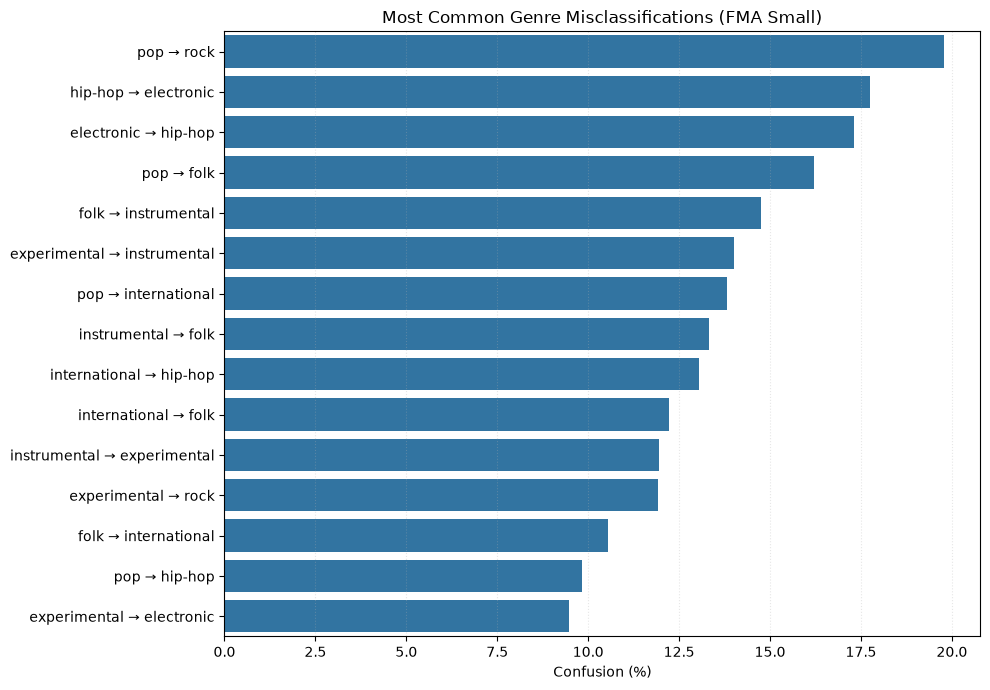

In [141]:
plot_df = (
    aggregate_genre_confusions_table
    .head(15)
    .copy()
)

plot_df["Confusion Pair"] = (
    plot_df["Actual Genre"]
    + " → "
    + plot_df["Predicted Genre"]
)

# --------------------------------------------------
# Plot
# --------------------------------------------------

plt.figure(figsize=(10, 7))

sns.barplot(
    data=plot_df,
    x="Confusion (%)",
    y="Confusion Pair",
    orient="h"
)

plt.title(
    "Most Common Genre Misclassifications (FMA Small)"
)

plt.xlabel("Confusion (%)")
plt.ylabel("")

plt.grid(
    axis="x",
    alpha=0.3,
    linestyle=":"
)

plt.tight_layout()
plt.show()

# 7. Leaderboards

## Table 15. Generalization Behavior Summary

In [142]:
generalization_summary_table = (
    training_behavior_df[
        [
            "model",
            "mean_generalization_gap",
            "mean_abs_gap",
            "overfitting_rate"
        ]
    ]
    .copy()
)

generalization_summary_table.columns = [
    "Architecture",
    "Mean Gap",
    "Absolute Gap",
    "Overfitting Rate"
]

generalization_summary_table = (
    generalization_summary_table
    .sort_values(
        "Absolute Gap"
    )
    .reset_index(drop=True)
)

display_table(generalization_summary_table)

Architecture,Mean Gap,Absolute Gap,Overfitting Rate
mobilenetv2,0.0737,0.0737,0.0000
vit,0.1017,0.1017,0.0750
cnn,0.2310,0.2310,0.7250
crnn,0.2410,0.2410,0.6500


### Comments
MobileNetV2 exhibited the strongest overall generalization behavior, producing the smallest mean generalization gap (0.074), the smallest absolute gap (0.074), and no overfitting events (0.000 overfitting rate). The architecture also achieved the highest overall classification accuracy (0.508), indicating that strong predictive performance was achieved without introducing substantial train-evaluation divergence.

ViT produced the second-smallest mean generalization gap (0.102) and a low overfitting rate (0.075). Despite these favorable generalization characteristics, ViT achieved the lowest overall classification accuracy (0.369), suggesting that the model generalized consistently but did not achieve competitive predictive performance under the evaluated training conditions.

CNN and CRNN exhibited substantially larger generalization penalties. CNN produced a mean and absolute generalization gap of approximately 0.231 and overfit in 72.5% of runs, while CRNN produced the largest generalization gap (0.241) and overfit in 65.0% of runs. Although CRNN achieved the second-highest classification accuracy (0.451), it did so while exhibiting the weakest overall generalization behavior.

These results indicate that architecture choice strongly influenced both predictive performance and robustness. Unlike the GTZAN experiments, the strongest-performing architecture also demonstrated the strongest generalization characteristics, resulting in a much clearer separation between model families.


## Table 16. Architecture Leaderboard

In [143]:
# --------------------------------------------------
# Architecture leaders
# --------------------------------------------------

overall_winner = (
    architecture_performance_df
    .sort_values(
        "mean_accuracy",
        ascending=False
    )
    .iloc[0]
)

efficiency_winner = (
    model_efficiency_df
    .sort_values(
        "mean_accuracy_per_million",
        ascending=False
    )
    .iloc[0]
)

short_duration_winner = (
    architecture_duration_summary_df[
        architecture_duration_summary_df[
            "duration_seconds"
        ] == 1
    ]
    .sort_values(
        "mean_accuracy",
        ascending=False
    )
    .iloc[0]
)

long_duration_winner = (
    architecture_duration_summary_df[
        architecture_duration_summary_df[
            "duration_seconds"
        ] == 30
    ]
    .sort_values(
        "mean_accuracy",
        ascending=False
    )
    .iloc[0]
)

duration_gain_winner = (
    duration_significance_table
    .sort_values(
        "Mean Accuracy Gain (%)",
        ascending=False
    )
    .iloc[0]
)

genre_specialist = (
    genre_recall_by_model_df.loc[
        genre_recall_by_model_df["recall"].idxmax()
    ]
)

# --------------------------------------------------
# Generalization leaders
# --------------------------------------------------

lowest_gap = (
    training_behavior_df
    .sort_values("mean_abs_gap")
    .iloc[0]
)

highest_gap = (
    training_behavior_df
    .sort_values(
        "mean_abs_gap",
        ascending=False
    )
    .iloc[0]
)

lowest_overfit = (
    training_behavior_df
    .sort_values("overfitting_rate")
    .iloc[0]
)

highest_overfit = (
    training_behavior_df
    .sort_values(
        "overfitting_rate",
        ascending=False
    )
    .iloc[0]
)

leaderboard_table = pd.DataFrame([
    {
        "Category": "Overall Accuracy Leader",
        "Architecture": overall_winner["model"],
        "Value": f"{overall_winner['mean_accuracy']:.3f}"
    },
    {
        "Category": "Most Parameter Efficient",
        "Architecture": efficiency_winner["model"],
        "Value": f"{efficiency_winner['mean_accuracy_per_million']:.3f}"
    },
    {
        "Category": "Best 1-Second Model",
        "Architecture": short_duration_winner["model"],
        "Value": f"{short_duration_winner['mean_accuracy']:.3f}"
    },
    {
        "Category": "Best 30-Second Model",
        "Architecture": long_duration_winner["model"],
        "Value": f"{long_duration_winner['mean_accuracy']:.3f}"
    },
    {
        "Category": "Largest Duration Gain",
        "Architecture": duration_gain_winner["Architecture"],
        "Value": (
            f"{duration_gain_winner['Mean Accuracy Gain (%)']:.1f}%"
        )
    },
    {
        "Category": "Best Genre Specialist",
        "Architecture": genre_specialist["model"],
        "Value": (
            f"{genre_specialist['genre']} "
            f"({genre_specialist['recall']:.3f})"
        )
    },
    {
        "Category": "Best Generalization",
        "Architecture": lowest_gap["model"],
        "Value": f"{lowest_gap['mean_abs_gap']:.3f}"
    },
    {
        "Category": "Lowest Overfitting Rate",
        "Architecture": lowest_overfit["model"],
        "Value": f"{lowest_overfit['overfitting_rate']:.3f}"
    },
    {
        "Category": "Weakest Generalization",
        "Architecture": highest_gap["model"],
        "Value": f"{highest_gap['mean_abs_gap']:.3f}"
    },
    {
        "Category": "Highest Overfitting Rate",
        "Architecture": highest_overfit["model"],
        "Value": f"{highest_overfit['overfitting_rate']:.3f}"
    }
])

display_table(leaderboard_table)

Category,Architecture,Value
Overall Accuracy Leader,mobilenetv2,0.508
Most Parameter Efficient,cnn,3.387
Best 1-Second Model,mobilenetv2,0.462
Best 30-Second Model,mobilenetv2,0.521
Largest Duration Gain,mobilenetv2,5.8%
Best Genre Specialist,mobilenetv2,hip-hop (0.639)
Best Generalization,mobilenetv2,0.074
Lowest Overfitting Rate,mobilenetv2,0.000
Weakest Generalization,crnn,0.241
Highest Overfitting Rate,cnn,0.725


### Comments
MobileNetV2 dominated the majority of evaluation categories. The architecture achieved the highest overall accuracy (0.508), the strongest performance at 1 second (0.462 accuracy), the strongest performance at 30 seconds (0.521 accuracy), and the largest duration-related improvement (+5.8%). MobileNetV2 also produced the strongest genre-specific performance, achieving 0.639 recall on Hip-Hop recordings.

The efficiency analysis identified CNN as the most parameter-efficient architecture, achieving 3.387 accuracy per million parameters while containing only 0.129 million parameters. Although CNN did not achieve the highest overall classification accuracy, it generated substantially more predictive performance per parameter than the larger architectures.

Generalization results were also led by MobileNetV2. The model achieved the smallest mean generalization gap (0.074) and no observed overfitting (0.000 overfitting rate). In contrast, CRNN exhibited the largest generalization gap (0.241) while CNN produced the highest overfitting rate (0.725). These results indicate that MobileNetV2 achieved a rare combination of strong predictive performance and strong generalization behavior.

Overall, the leaderboard demonstrates a much clearer hierarchy than was observed in GTZAN. MobileNetV2 occupied the top position across most evaluation criteria, whereas CNN's primary advantage was parameter efficiency rather than raw classification performance.


# 8. Summary of Findings

### Audio Duration Improved Classification Performance, but Effects Were Smaller Than Expected
Figure 5 and Table 6 show that classification performance generally improved as audio duration increased from 1-second to 30-second excerpts. However, Table 8 demonstrates that duration effects were not uniform across architectures. MobileNetV2 exhibited the largest improvement between 1-second and 30-second excerpts (+5.8%), followed closely by CRNN (+5.6%). ViT achieved a smaller but statistically significant gain (+1.8%), while CNN exhibited only a modest, non-significant improvement (+1.4%). These findings indicate that additional listening context remained beneficial, although the magnitude of the effect was substantially smaller than the largest gains observed on GTZAN.

### MobileNetV2 Achieved the Strongest Overall Classification Performance
As shown in Figure 1 and Table 3, MobileNetV2 achieved the highest overall classification accuracy (0.508) and F1 score (0.499) among the evaluated architectures. Table 16 further shows that MobileNetV2 achieved the highest performance on both 1-second excerpts (0.462 accuracy) and 30-second excerpts (0.521 accuracy). These findings indicate that MobileNetV2 maintained its performance advantage across all evaluated durations.

### Architecture Rankings Remained Relatively Stable Across Durations
Unlike GTZAN, where performance leadership shifted as audio duration increased, Figure 7 and Table 7 show that architecture rankings remained comparatively stable throughout the FMA Small study. MobileNetV2 consistently occupied the highest performance tier, ViT consistently occupied the lowest, and CNN and CRNN generally formed an intermediate group. These results suggest that duration affected performance, but did not substantially alter the relative ordering of architectures.

### CNN Provided the Strongest Parameter Efficiency
Figure 4 and Table 4 demonstrate that CNN achieved the highest parameter efficiency, producing 3.387 units of accuracy per million parameters while using only 0.129 million parameters. Although MobileNetV2 achieved higher overall classification performance, CNN generated substantially more predictive performance relative to model size. These results suggest that architecture efficiency and predictive performance represent distinct evaluation criteria.

### Duration Effects Varied Substantially Across Genres
Figure 8 and Table 9 reveal substantial variation in genre sensitivity to audio duration. Folk exhibited the largest absolute improvement, increasing from 0.444 recall at 1 second to 0.575 recall at 30 seconds (+0.131 recall). Hip-Hop exhibited the second-largest improvement, increasing from 0.477 to 0.585 recall (+0.108 recall). These results indicate that additional listening context was particularly valuable for specific genres rather than uniformly beneficial across the entire dataset.

### Several Genres Showed Little or No Benefit From Longer Excerpts
Table 9 indicates that not all genres benefited from increased duration. International improved only from 0.437 to 0.447 recall (+0.010), while Pop declined slightly from 0.122 to 0.117 recall (−0.004). Instrumental decreased from 0.476 to 0.439 recall (−0.037). Confidence intervals for these genres included zero, indicating that the observed changes were not statistically supported. These findings suggest that additional clip length is not universally beneficial for genre recognition.

### Pop Remained Difficult Regardless of Architecture or Duration
Figure 8 and Table 9 identify Pop as the weakest-performing genre in the study. Mean recall remained low at every duration, ranging from 0.122 recall at 1 second to 0.117 recall at 30 seconds. Figure 11 and Table 14 further show that Pop was heavily involved in the most common classification errors, including Pop → Rock (19.8%), Pop → Folk (16.2%), and Pop → International (13.8%). These findings suggest that classification difficulty was driven primarily by genre overlap rather than insufficient listening context.

### MobileNetV2 Dominated Genre-Level Performance
Figure 9 and Table 10 demonstrate that architecture performance varied across genres, but unlike GTZAN, one architecture emerged as the dominant performer. MobileNetV2 achieved the highest recall in 7 of 8 genres, including Hip-Hop (0.639 recall), Folk (0.601 recall), Electronic (0.551 recall), and International (0.567 recall). CRNN achieved the highest recall only for Rock (0.578 recall). These results indicate that MobileNetV2 consistently extracted useful genre-discriminative information across the dataset.

### Generalization Characteristics Varied Across Architectures
Figure 3 and Table 5 reveal substantial differences in generalization behavior. MobileNetV2 achieved the smallest absolute generalization gap (0.074) and a zero overfitting rate (0.000), indicating very strong agreement between training and evaluation performance. In contrast, CRNN produced the largest absolute generalization gap (0.241) and CNN achieved the highest overfitting rate (0.725). These findings demonstrate that predictive performance and generalization quality remained distinct dimensions of model evaluation.

### Strong Classification Performance and Strong Generalization Coincided
Unlike the GTZAN study, where the strongest classifier and strongest generalizer were different architectures, Figure 1 and Table 5 show that MobileNetV2 simultaneously achieved the highest classification accuracy (0.508) and the strongest generalization behavior (0.074 gap). These results demonstrate that strong predictive performance and strong robustness can coexist within the same architecture when transfer learning is effectively utilized.

### Classification Errors Followed Consistent Patterns
Figure 11 and Table 14 indicate that several genre confusions persisted across architectures, durations, and experimental conditions. The strongest confusion pair involved Hip-Hop ↔ Electronic, while Folk ↔ Instrumental and Pop ↔ Rock also occurred frequently. These recurring error patterns suggest that several genre boundaries remained difficult to separate using the available acoustic representations. Additional listening context reduced some errors but did not eliminate the most persistent confusion pairs.

### Noted Conclusions
Taken together, the evidence presented in Figures 1 through 10 and Tables 1 through 16 demonstrates that audio duration remained an important but architecture-dependent and genre-dependent factor in music genre classification. MobileNetV2 achieved the strongest overall performance (0.508 accuracy), exhibited the largest statistically significant duration gain (+5.8%), and demonstrated the strongest generalization behavior (0.074 absolute gap, 0.000 overfitting rate). CNN achieved the highest parameter efficiency (3.387 accuracy per million parameters), while CRNN exhibited duration sensitivity comparable to MobileNetV2 despite substantially larger generalization penalties.

The genre analyses further demonstrate that duration effects were concentrated within a small subset of genres. Folk and Hip-Hop benefited substantially from longer listening windows, whereas Pop and Instrumental exhibited little or no measurable benefit. The error analyses revealed persistent confusion clusters that remained present even at longer durations, indicating that several classification challenges were driven by overlapping genre characteristics rather than insufficient listening context alone.

Collectively, these results indicate that architecture selection, clip length, genre structure, generalization behavior, and dataset characteristics all contribute meaningfully to classification performance. While duration effects persisted on FMA Small, the magnitude of those effects was substantially smaller than those observed on GTZAN, suggesting that the value of additional listening context depends strongly on the dataset and genre taxonomy under evaluation.





